<a href="{{ colab_base_laboratorios }}/Laboratorio_07_abc_modelo_v2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Lab 7: ABC del aprendizaje de máquina

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pylab as plt

## 1. Entendimiento de los datos

El primer paso consiste en comprender el origen y la naturaleza de los datos. Es fundamental identificar la fuente (por ejemplo, si provienen de un censo, sensores o registros operacionales), así como la unidad de observación, es decir, qué representa cada fila: una persona, un distrito, una vivienda, entre otros.

También es importante reconocer el tipo de variables presentes en el conjunto de datos, distinguiendo entre variables numéricas, categóricas, espaciales o temporales. En esencia, la pregunta clave en esta etapa es: ¿qué representa físicamente cada observación?


## 2. Calidad de datos (Data Quality)

Una vez entendido el dataset, se debe evaluar su calidad. Esto implica analizar la presencia de valores faltantes y determinar si su ausencia es aleatoria o responde a algún patrón estructural. Asimismo, es necesario examinar los valores atípicos (outliers), diferenciando entre posibles errores de medición y fenómenos reales del sistema.

Adicionalmente, se debe verificar la consistencia de los datos, asegurando que las unidades sean correctas y que los valores se encuentren dentro de rangos razonables.


## 3. Análisis exploratorio (EDA)

El análisis exploratorio permite obtener una primera comprensión de la estructura del dataset. En esta fase se estudian las distribuciones de las variables mediante histogramas o funciones de densidad, lo que permite identificar asimetrías, concentraciones o comportamientos anómalos.

También se analizan las relaciones entre variables, por ejemplo, mediante correlaciones o gráficos de dispersión. Finalmente, es útil examinar la geometría del conjunto de datos, identificando posibles agrupaciones (clusters) o patrones espaciales como gradientes.

## 5. Feature Engineering

En esta etapa se transforman las variables originales para construir representaciones más informativas del problema. Esto puede implicar la creación de nuevas variables derivadas o la aplicación de transformaciones que faciliten el modelado.

Por ejemplo, es común definir medidas de densidad como:

$$
\text{rooms\_per\_household} = \frac{\text{total\_rooms}}{\text{households}}
$$

o variables como el número de personas por hogar. También pueden aplicarse transformaciones como el logaritmo de la variable objetivo:

$$
\log(y)
$$


## 6. Partición del dataset

Para evaluar correctamente el desempeño de los modelos, es necesario dividir el conjunto de datos en subconjuntos de entrenamiento, validación y prueba. Esta separación permite evitar el sobreajuste y obtener estimaciones realistas del rendimiento.

Es importante enfatizar que el conjunto de prueba debe permanecer completamente aislado durante el desarrollo del modelo.


## 7. Modelado

En función del problema planteado, se selecciona un modelo adecuado, como regresión lineal, árboles de decisión, métodos de ensamble o redes neuronales. En términos generales, el objetivo es aproximar una relación funcional entre las variables de entrada y la variable objetivo:

$$
y = f_\theta(X)
$$


## 8. Entrenamiento

El entrenamiento consiste en ajustar los parámetros del modelo mediante la minimización de una función de costo. Un ejemplo común en problemas de regresión es el error cuadrático medio:

$$
\mathcal{L}(\theta) = \frac{1}{n} \sum (y_i - \hat{y}_i)^2
$$

Este proceso se realiza mediante algoritmos de optimización, como el gradiente descendente.


## 9. Evaluación

Una vez entrenado el modelo, se evalúa su desempeño utilizando métricas adecuadas como el error absoluto medio (MAE), el error cuadrático medio (RMSE) o el coeficiente de determinación (R²):

$$
\text{MAE} = \frac{1}{n}\sum |y_i - \hat{y}_i|
$$

Es fundamental que esta evaluación se realice sobre datos no utilizados durante el entrenamiento.


## 10. Interpretabilidad

Además del rendimiento, es importante comprender cómo el modelo utiliza las variables. Esto incluye analizar la importancia de las variables y la sensibilidad de las predicciones frente a cambios en las entradas.


## 11. Incertidumbre

Todo modelo presenta cierto grado de incertidumbre, por lo que es necesario cuantificarla. Esto puede hacerse mediante intervalos de confianza, técnicas de remuestreo como bootstrap o analizando la variabilidad de las predicciones.


## 12. Validación del modelo

La validación busca asegurar que el modelo generaliza adecuadamente a nuevos datos. Esto implica evaluar su robustez frente a diferentes particiones o condiciones.



## 14. Comunicación

Los resultados deben presentarse de forma clara y coherente, apoyándose en visualizaciones adecuadas y evitando interpretaciones exageradas. La comunicación es clave para que el análisis tenga impacto.

## 15. Deployment

En contextos aplicados, el modelo puede ser desplegado en producción, por ejemplo, mediante una API o procesos batch. Esto permite su uso en sistemas reales.

## 16. Monitoreo y drift

Una vez en producción, es necesario monitorear el comportamiento del modelo, especialmente posibles cambios en la distribución de los datos:

$$
P_{\text{train}}(X) \neq P_{\text{prod}}(X)
$$

Estos cambios pueden afectar el desempeño del modelo con el tiempo.

## 17. Reproducibilidad

Finalmente, todo el proceso debe ser reproducible. Esto implica mantener un adecuado versionado de los datos, código limpio, control de semillas aleatorias y registro de experimentos.

# Problema

El dataset de viviendas de California corresponde a un conjunto de datos basado en el censo de 1990, que contiene información sobre los precios medios de las viviendas junto con diversas características demográficas y estructurales de los distritos en el estado de California.

A continuación, se describen las variables incluidas en el dataset:

- **longitude**: longitud del centroide del distrito (en grados). Indica la posición geográfica en el eje este-oeste.

- **latitude**: latitud del centroide del distrito (en grados). Indica la posición geográfica en el eje norte-sur.

- **housing_median_age**: edad media de las viviendas en el distrito (en años). Proporciona una aproximación al estado y antigüedad de las construcciones.

- **total_rooms**: número total de habitaciones en el distrito, sin distinción de tipo. Refleja la capacidad habitacional agregada.

- **total_bedrooms**: número total de dormitorios en el distrito. Representa los espacios destinados al descanso dentro de las viviendas.

- **population**: número total de habitantes del distrito. Permite inferir la densidad poblacional y la presión sobre la vivienda.

- **households**: número de hogares en el distrito. Un hogar corresponde a un grupo de personas que habitan una misma vivienda; esta variable describe la estructura residencial.

- **median_income**: ingreso medio por hogar (expresado en miles de dólares, $10^3$ USD). Indica el nivel socioeconómico de los residentes.

- **median_house_value**: valor medio de las viviendas (expresado en cientos de miles de dólares, $10^5$ USD). Esta es la **variable objetivo** del problema, ya que representa el precio promedio de las propiedades en cada distrito.

# 1.0 Análisis del data frame

1. Leer el data frame en formato csv en la dirección https://raw.githubusercontent.com/hernansalinas/Curso_aprendizaje_estadistico/main/datasets/Sesion_07_housing.csv

2. Entender  el estado de los datos, para ello puedo emplear los comandos básicos del pandas

  ```python
  df.info()
  df.describe()
  df.isnull().sum()
  df.isna().sum()
```
Estos dos últimos son equivalentes.

3. ¿Cuántas variables tiene el dataset y de qué tipo son?
4. ¿Existen valores faltantes? ¿En qué variables estan? ¿cuántos son?

5. Determinar los elementos únicos dentro de la columna ocean_proximity.

6. Para las columnas

```python
cols = ["housing_median_age",	"total_rooms",	"total_bedrooms",	"population",	"households",	"median_income",	"median_house_value"]
```

Determinar el promedio de cada una de las columnas asociado a cada elementos unico de ocean_proximity, intenta con la operación groupby.

7. Construye un histograma para cada columna, puede emplear la libreria de seaborn.

### [Diagrama de caja](https://en.wikipedia.org/wiki/Box_plot)


### Diagrama de caja

![box](https://upload.wikimedia.org/wikipedia/commons/e/ed/Box_Plot_Picture.png)



### Interpretación de un diagrama de caja

- Desde el minimo al valor más bajo de la caja: primer cuartil, 25% de los datos
- Desde el valor más bajo de la caja hasta la mediana: segundo cuartil, 25% de los datos
- Desde la mediana hasta el valor mas alto de la caja : tercer cuartil, 25% de los datos
- Desde el valor mas alto de la caja hasta el máximo: Cuarto  cuartil, 25% de los datos


El rango intercuartil $IQR = Q_3-Q_1$ permite definir que datos pueden ser atípicos, basado en los siguientes limites:

$Max = Q3 + 1.5IQR$

$Min = Q1 - 1.5IQR$



El cuartil puede ser determinado como sigue:

Para calcular los cuartiles de una lista de números:

- Ordenar los números de menor a mayor.
- Calcular la posición de cada cuartil usando la fórmula: Q = a (N+1) / 4, donde Q es la posición del cuartil, a es el número del cuartil (1, 2 o 3), y N es el número total de datos.
- Si la posición del cuartil es un número entero, el valor del cuartil es el dato que está en esa posición.
- Si la posición del cuartil es un número decimal, el valor del cuartil se interpola usando la fórmula: Q = x + d (y - x), donde Q es el valor del cuartil, x es el dato anterior a la posición del cuartil, y es el dato posterior a la posición del cuartil, y d es la parte decimal de la posición del cuartil.


Veamos un ejemplo:



In [ ]:
T = np.array([52, 57, 57, 58, 63, 66, 66, 67, 67, 68, 69, 70, 70, 70, 70, 72, 73, 75, 75, 76, 76, 78, 79, 89])
Tsort = np.sort(T)
print(len(T))
print(f"T sort:{Tsort}")
len(T)/4

24
T sort:[52 57 57 58 63 66 66 67 67 68 69 70 70 70 70 72 73 75 75 76 76 78 79 89]


6.0

In [ ]:

IQR=9
max_ = 75 + 1.5*IQR
min_ = 66 - 1.5*IQR
print(max_)
print(min_)
plt.boxplot(T)

8. Empleando el siguiente código realiza el gráfico boxplot,
```python
#draw boxplot
df.boxplot(column="median_house_value", by='ocean_proximity', sym = 'k.', figsize=(18,6))
#set title
plt.title('Boxplot for comparing price per living space for each city')
plt.show()
```

9. Determina la matrix de correlación.

### [Matrix de correlación](https://en.wikipedia.org/wiki/Correlation)

¿Como se determina la matrix de correlación?

![Matrix de correlación](https://upload.wikimedia.org/wikipedia/commons/thumb/d/d4/Correlation_examples2.svg/1920px-Correlation_examples2.svg.png)



```python
corr_matrix = df.corr()
corr_matrix

plt.figure(figsize = (10,6))
sns.heatmap(corr_matrix, annot = True, cmap = "coolwarm", center=0)
plt.show()
```

10. con las columnas, realiza un grafico pairplot empleando seaborn  de python.
```python
cols = ["median_house_value", "median_income", "total_rooms","housing_median_age"]
```

11. Realiza un scatter plot con la libreria sea born de python, el color del grafico puede ser empleado con la columna median_house_value

# 2.0 Preparacion del data frame

## Evitar el data *Snooping bias*.

En algunos casos se sugiere dividir los datos en entrenamiento y test desde el principio dado que el cerebro puede sobreajustar el dataset y los resultados no significativos se pueden volver significativos. El procedimiento correcto es probar cualquier hipótesis en un conjunto de datos que no se utilizó para generar las hipótesis inicial.


## *Sampling bias*

Si el dataset es lo suficientemente grande un muestreo aleatorio de la muestra puede ser considerado, sin embargo si la muestra es pequena se debe garantizar homegeniedad en el dataset de entrenamiento.


Ejemplo:

Por ejemplo, la población de EE. UU. esta compuesto por un 51,3 % de mujeres y un 48,7 % de hombres, por lo que una encuesta bien realizada en EEUU
trata de mantener esta proporción en la muestra: 513 mujeres y 487 hombres. Esto se llama muestreo estratificado(stratified sampling): la población se divide en subgrupos homogéneos llamados estratos(strata), y se muestrea el número correcto de instancias de cada estrato para garantizar que el
El conjunto de prueba es representativo de la población general. Si usaran muestras puramente aleatorias, habría alrededor del 12% de posibilidades de muestrear un conjunto de prueba sesgado con menos del 49% de mujeres o más del 54% de mujeres. De cualquier manera, los resultados de la encuesta serían
significativamente sesgada.


12. ¿Las siguiente linea es adecuada para separar el dataframe en datos de entrenamiento de test?, ¿que pasa en la división de los datos?


```python
from sklearn.model_selection import train_test_split

# ¿Es significativa la muestra que se esta considerando?
train_set, test_set \
  = train_test_split(df, test_size = 0.2, random_state = 42)

print(len(train_set))
print(len(test_set))

```


13. División del dataset en grupos:


La siguiente división puede ser realizada  basada en la experticie de lo que se esta analizando, y sobre ello se debe tomar una muestra significativa. Una posible solución al problema puede ser el siguiente:

```python
df["income_cat"] = pd.cut(df["median_income"],
                               bins=[0., 1.5, 3.0, 4.5, 6., np.inf],
                               labels=[1, 2, 3, 4, 5])


df.income_cat.hist()


```

La forma automatica de realizar la división puede ser la siguiente:

```python
from sklearn.model_selection import StratifiedShuffleSplit

split = StratifiedShuffleSplit(n_splits = 1, test_size=0.2, random_state=42)

for train_index, test_index in split.split(df, df["income_cat"]):
  strat_train_set = df.loc[train_index]
  strat_test_set = df.loc[test_index]

```


Analiza las siguiente lineas de código y saca conclusiones referente a las proporciones del dataset.

```python
df["income_cat"].value_counts() / len(df)

strat_train_set["income_cat"].value_counts() / len(strat_train_set)

strat_test_set["income_cat"].value_counts() / len(strat_test_set)


train_set, test_set \
  = train_test_split(df, test_size = 0.2, random_state = 7)

train_set["income_cat"].value_counts() / len(train_set)
```

un comparativo general puede ser estructurado de la siguente forma, analiza  los errores:

```python
def income_cat_proportions(data):
    return data["income_cat"].value_counts() / len(data)

train_set, test_set = train_test_split(df, test_size = 0.2, random_state = 42)

compare_props = pd.DataFrame({
    "Overall": income_cat_proportions(df),
    "Stratified": income_cat_proportions(strat_test_set),
    "Random": income_cat_proportions(test_set),
}).sort_index()
compare_props["Rand. %error"] =abs( 100 * compare_props["Random"] / compare_props["Overall"] - 100)
compare_props["Strat. %error"] =abs( 100 * compare_props["Stratified"] / compare_props["Overall"] - 100)
```

13. Puedes agregar nuevas variables al dataframe para el análisis, por ejemplo:
```python
df_train["rooms_per_household"] = df_train["total_rooms"]/df_train["households"]
df_train["bedrooms_per_room"] = df_train["total_bedrooms"]/df_train["total_rooms"]
df_train["population_per_household"]=df_train["population"]/df_train["households"]
```




# Limpieza de datos

Lo que sigue son códigos que pueden servir para limpiar los datos.

```python

df.isnull().sum()


#df_train.dropna(subset=["total_bedrooms"]) #Eliminar los nan
#df_train.drop("total_bedrooms", axis=1)  # Eliminar la columna
median = df_train["total_bedrooms"].median()
q=df_train["total_bedrooms"].fillna(median).copy()


q=pd.DataFrame(q)

q.isnull().sum()

```

##imputer

Forma automática para tratar los datos (Asegurate de trabajar con las columnas numéricas):


```python
from sklearn.impute import SimpleImputer
#imputer = Imputer(strategy="median")

df_train_num = df_train.drop("ocean_proximity", axis=1)

imp_mean = SimpleImputer( strategy='mean')

imp_mean.fit(df_train_num)

imp_mean.statistics_
```

14. Compara las siguientes variables:
```python
imp_mean.statistics_
df_train_num.median()
```


```python
Constuye la matriz de características:

X = imp_mean.transform(df)
housing_tr = pd.DataFrame(X, columns=df_train_num.columns)
```


# Manejo de texto y atributos categóricos
15.  ¿Qué realizan las siguientes lineas de código?

```
from sklearn.preprocessing import OneHotEncoder
df_train["ocean_proximity"].unique()
housing_cat=df_train[["ocean_proximity"]]
housing_cat

cat_encoder = OneHotEncoder(sparse_output=False)
housing_cat_1hot = cat_encoder.fit_transform(housing_cat)
print(housing_cat_1hot)
print(cat_encoder.categories_)


df_cat_1hot = pd.DataFrame(housing_cat_1hot, columns = cat_encoder.categories_[0])

housing_tr_ = housing_tr.join(df_cat_1hot)
```


# Escalamiento de variables

16. Las variables pueden ser escaladas como sigue:

```python

cols=["longitude", "latitude",	"housing_median_age",	"total_rooms",\
      "total_bedrooms",	"population",	"households",	"median_income",\
      "<1H OCEAN",	"INLAND",	"ISLAND",	"NEAR BAY", "NEAR OCEAN"]


housing_scale=housing_tr_[cols]
housing_scale


from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
scaler.fit(housing_scale)

X = scaler.transform(housing_scale)


housing_prepared = pd.DataFrame(X, columns = housing_scale.columns)

```


17. Para todos los pasos anteriores, contruye ordenadamente los pasos limpieza, escalamiento de variables, manejo de texto y atributos categóricos para tener el data frame listo para el análisis. Recuerda dividir el data frame en datos de entrenamiento y de test con la correcta estractificación. Genera dos data frame: housing_train, housing_test, cada una, debe tener las caracteristicas y los datos etiquetados.

1. ¿que puede concluir respecto al modelo empleado?
2. ¿El modelo de regresión lineal es valido para lo construido,
3. ¿qué informacion nos da el score?
4. ¿Puede ser ajustado a otro modelo?
5. ¿Como puede autmatizar todo el proceso empleando pipelines?








`# 3.0 Modelo base interpretable con PCA`

**23.** La regresión lineal de los puntos 17 a 20 usa todas las variables preparadas. Construye ahora un modelo con muy pocas variables, obtenidas a partir de la matriz de covarianzas, y compáralo con ella.

- Parte de la misma división estratificada del punto 13 (división del dataset) y de las mismas variables numéricas del punto 17. Calcula las componentes principales con PCA y decide cuántas conservar.
- Relaciona las cargas de las componentes con lo que viste en la matriz de correlación (punto 9) y en el pairplot (punto 10). ¿Qué grupos de variables resumen?
- Revisa las variables creadas en el punto 13 (nuevas variables), como `rooms_per_household` o `bedrooms_per_room`. ¿Aportan información que las componentes no capturan?
- En el punto 16 se escaló con `MinMaxScaler`. ¿Es la elección adecuada para PCA? Justifica tu decisión.
- Ajusta tu modelo reducido y compara su `score` con el de la regresión analizada en el punto 20. ¿Cuánto $R^2$ se pierde por usar tan pocas variables?
- Con un test de permutaciones, argumenta si tu modelo reducido captura algo real.
- Compara los coeficientes de ambos modelos. ¿Cuál es más fácil de interpretar y por qué?



`# 4.0 Regularización: L2 vs L1`

**24.** Responde con evidencia la pregunta del punto 21, *"¿Puede ser ajustado a otro modelo?"*, extendiendo la regresión lineal del punto 17 en dos pasos.

- Aumenta su complejidad, por ejemplo con términos polinomiales, hasta que sobreajuste. Muéstralo comparando su error con el de la regresión original.
- Controla el sobreajuste con Ridge (L2) y con Lasso (L1). Analiza cómo cambia el paso de gradiente descendente con el término L2.
- Grafica cómo evolucionan los coeficientes y el error al variar la intensidad de la regularización y explica las diferencias entre L1 y L2.
- Observa qué hace cada método con las variables colineales que identificaste en el punto 23.
- Organiza todo en un `Pipeline`, retomando lo planteado en el punto 22. Selecciona los hiperparámetros sin tocar el conjunto de test.


 `# 5.0 Comparación final`

**25.** Evalúa en `housing_test`, con la misma partición y la misma métrica, cuatro modelos:

- la regresión lineal del punto 17,
- el modelo reducido del punto 23,
- el mejor Ridge del punto 24,
- el mejor Lasso del punto 24.

Después responde:

- Con bootstrap, determina si las diferencias de desempeño frente a la regresión del punto 17 son estadísticamente significativas.
- ¿Las variables que conserva Lasso se relacionan con las que destacó PCA? ¿Por qué?
- Vuelve a responder los puntos 18 a 20 a la luz de esta comparación. ¿Cambió tu conclusión sobre la regresión lineal original?
- ¿Cuánto desempeño se pierde a cambio de interpretabilidad? ¿Qué modelo presentarías a alguien que no es especialista, y por qué?

# Solucion Laboratorio 7

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Analisis del data frame

In [ ]:
url = "https://raw.githubusercontent.com/hernansalinas/Curso_aprendizaje_estadistico/main/datasets/Sesion_07_housing.csv"
df = pd.read_csv(url)
print(df.shape) #(filas, columnas)
df.head()

(20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [ ]:
df.describe().round(2)

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.00,20640.00,20640.00,20640.00,20433.00,20640.00,20640.00,20640.00,20640.00
mean,-119.57,35.63,28.64,2635.76,537.87,1425.48,499.54,3.87,206855.82
std,2.00,2.14,12.59,2181.62,421.39,1132.46,382.33,1.90,115395.62
min,-124.35,32.54,1.00,2.00,1.00,3.00,1.00,0.50,14999.00
25%,-121.80,33.93,18.00,1447.75,296.00,787.00,280.00,2.56,119600.00
50%,-118.49,34.26,29.00,2127.00,435.00,1166.00,409.00,3.53,179700.00
75%,-118.01,37.71,37.00,3148.00,647.00,1725.00,605.00,4.74,264725.00
max,-114.31,41.95,52.00,39320.00,6445.00,35682.00,6082.00,15.00,500001.00


In [ ]:
print(df.isnull().sum())

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64


El dataset tiene 20640 filas y 10 variables. Nueve son numericas de tipo float64 y una es de texto, ocean_proximity, que es categorica. Solo hay valores 207 faltantes en total_bedrooms

In [ ]:
# Categorias de ocean_proximity y cuantos distritos hay en cada una
print(df["ocean_proximity"].unique())
print(df["ocean_proximity"].value_counts())

['NEAR BAY' '<1H OCEAN' 'INLAND' 'NEAR OCEAN' 'ISLAND']
ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64


In [ ]:
cols = ["housing_median_age", "total_rooms", "total_bedrooms", "population", "households", "median_income", "median_house_value"]

# Promedio de cada columna segun la cercania al mar
df.groupby("ocean_proximity")[cols].mean().round(1)

,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
ocean_proximity,,,,,,,
<1H OCEAN,29.3,2628.3,546.5,1520.3,517.7,4.2,240084.3
INLAND,24.3,2717.7,533.9,1391.0,477.4,3.2,124805.4
ISLAND,42.4,1574.6,420.4,668.0,276.6,2.7,380440.0
NEAR BAY,37.7,2493.6,514.2,1230.3,488.6,4.2,259212.3
NEAR OCEAN,29.3,2583.7,538.6,1354.0,501.2,4.0,249434.0


Los distritos INLAND son los mas baratos, con un valor promedio de 124805 dolares, casi la mitad de los que estan cerca del mar, y tambien tienen el ingreso mas bajo entre las categorias grandes. ISLAND tiene el promedio mas alto pero son solo 5 distritos, asi que ese numero no es confiable.

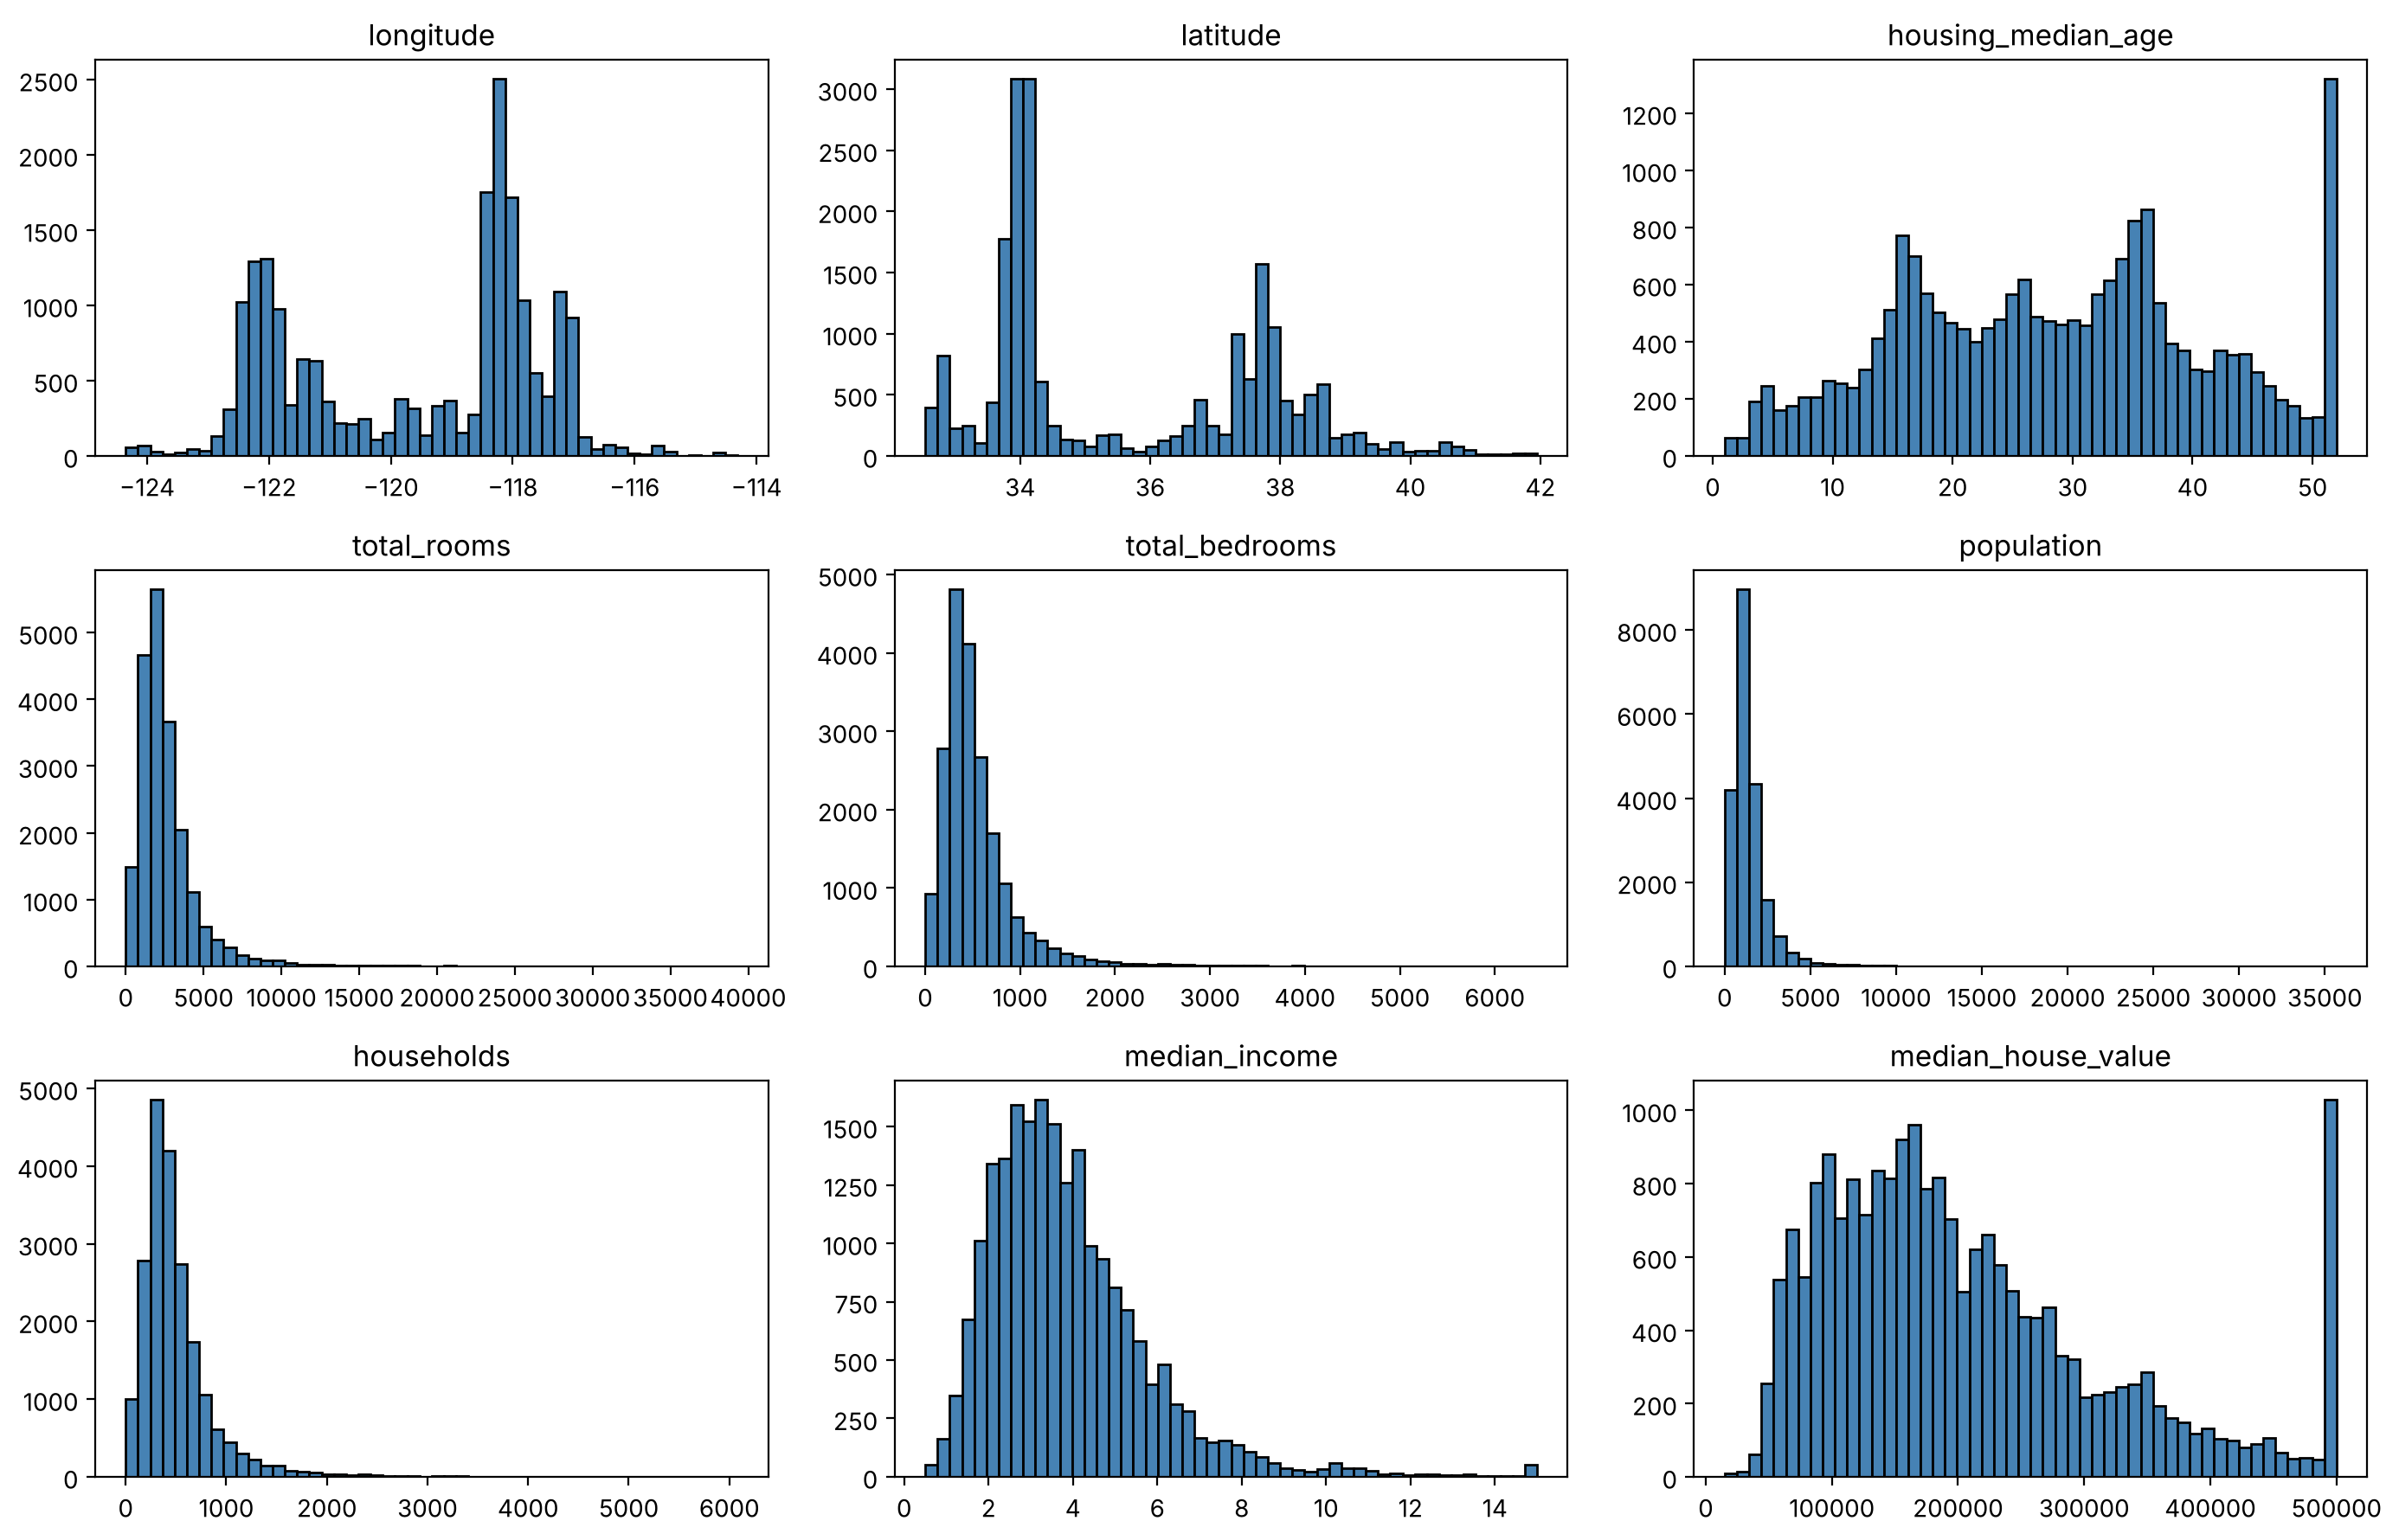

In [ ]:
df.hist(bins=50, color="steelblue", grid=False, figsize=(14, 9))
plt.tight_layout()
plt.show()

Las variables de conteo (total_rooms, total_bedrooms, population y households) estan muy sesgadas a la derecha, casi todos los distritos tienen valores pequeños y unos pocos tienen valores enormes. En housing_median_age y en median_house_value hay una barra alta al final, lo que indica que los datos fueron recortados en 52 años y en 500001 dolares. Longitud y latitud tienen dos picos, es decir que los distritos se concentran en dos zonas del estado.

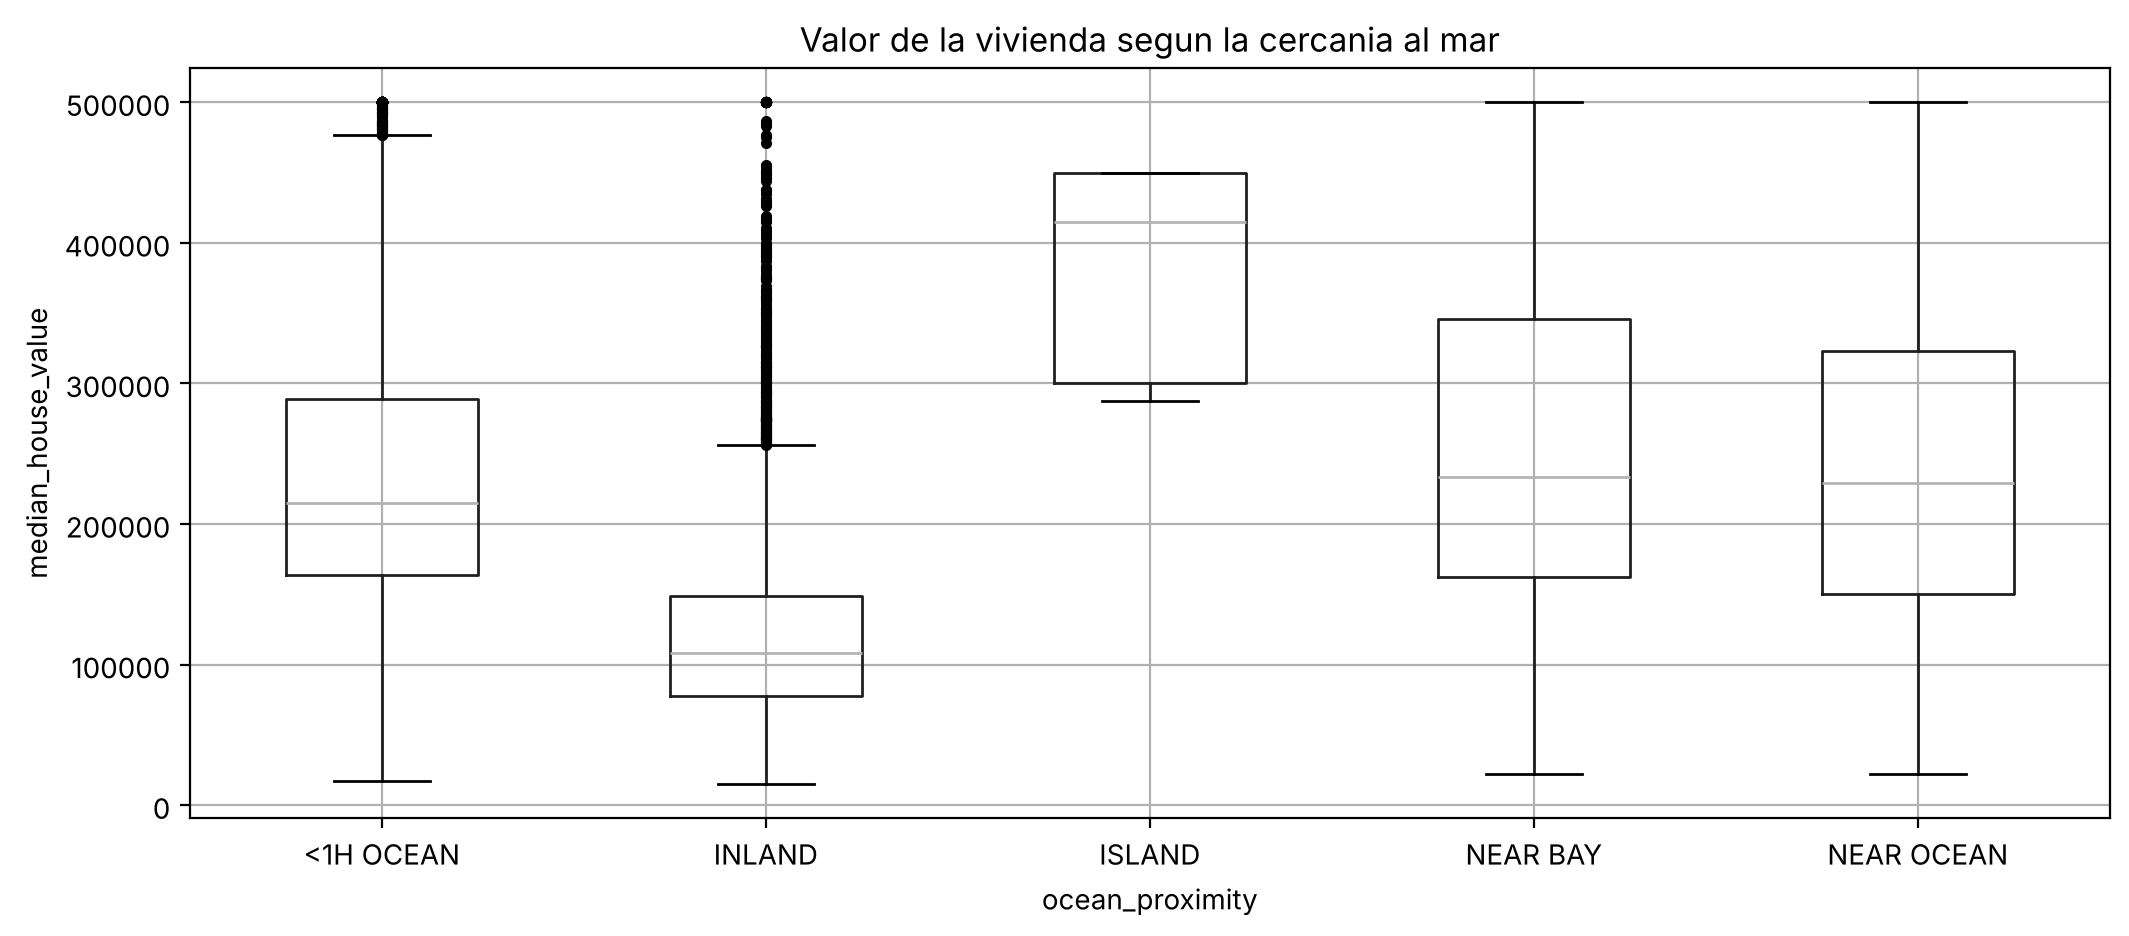

In [ ]:
df.boxplot(column="median_house_value", by="ocean_proximity", sym="k.", figsize=(12, 5))
plt.title("Valor de la vivienda segun la cercania al mar")
plt.suptitle("") # quita el titulo automatico de pandas
plt.xlabel("ocean_proximity")
plt.ylabel("median_house_value")
plt.show()

La caja de INLAND queda claramente por debajo de las demas, las tres categorias cercanas al agua tienen medianas parecidas entre si. ISLAND se ve alta pero tiene muy pocos datos.

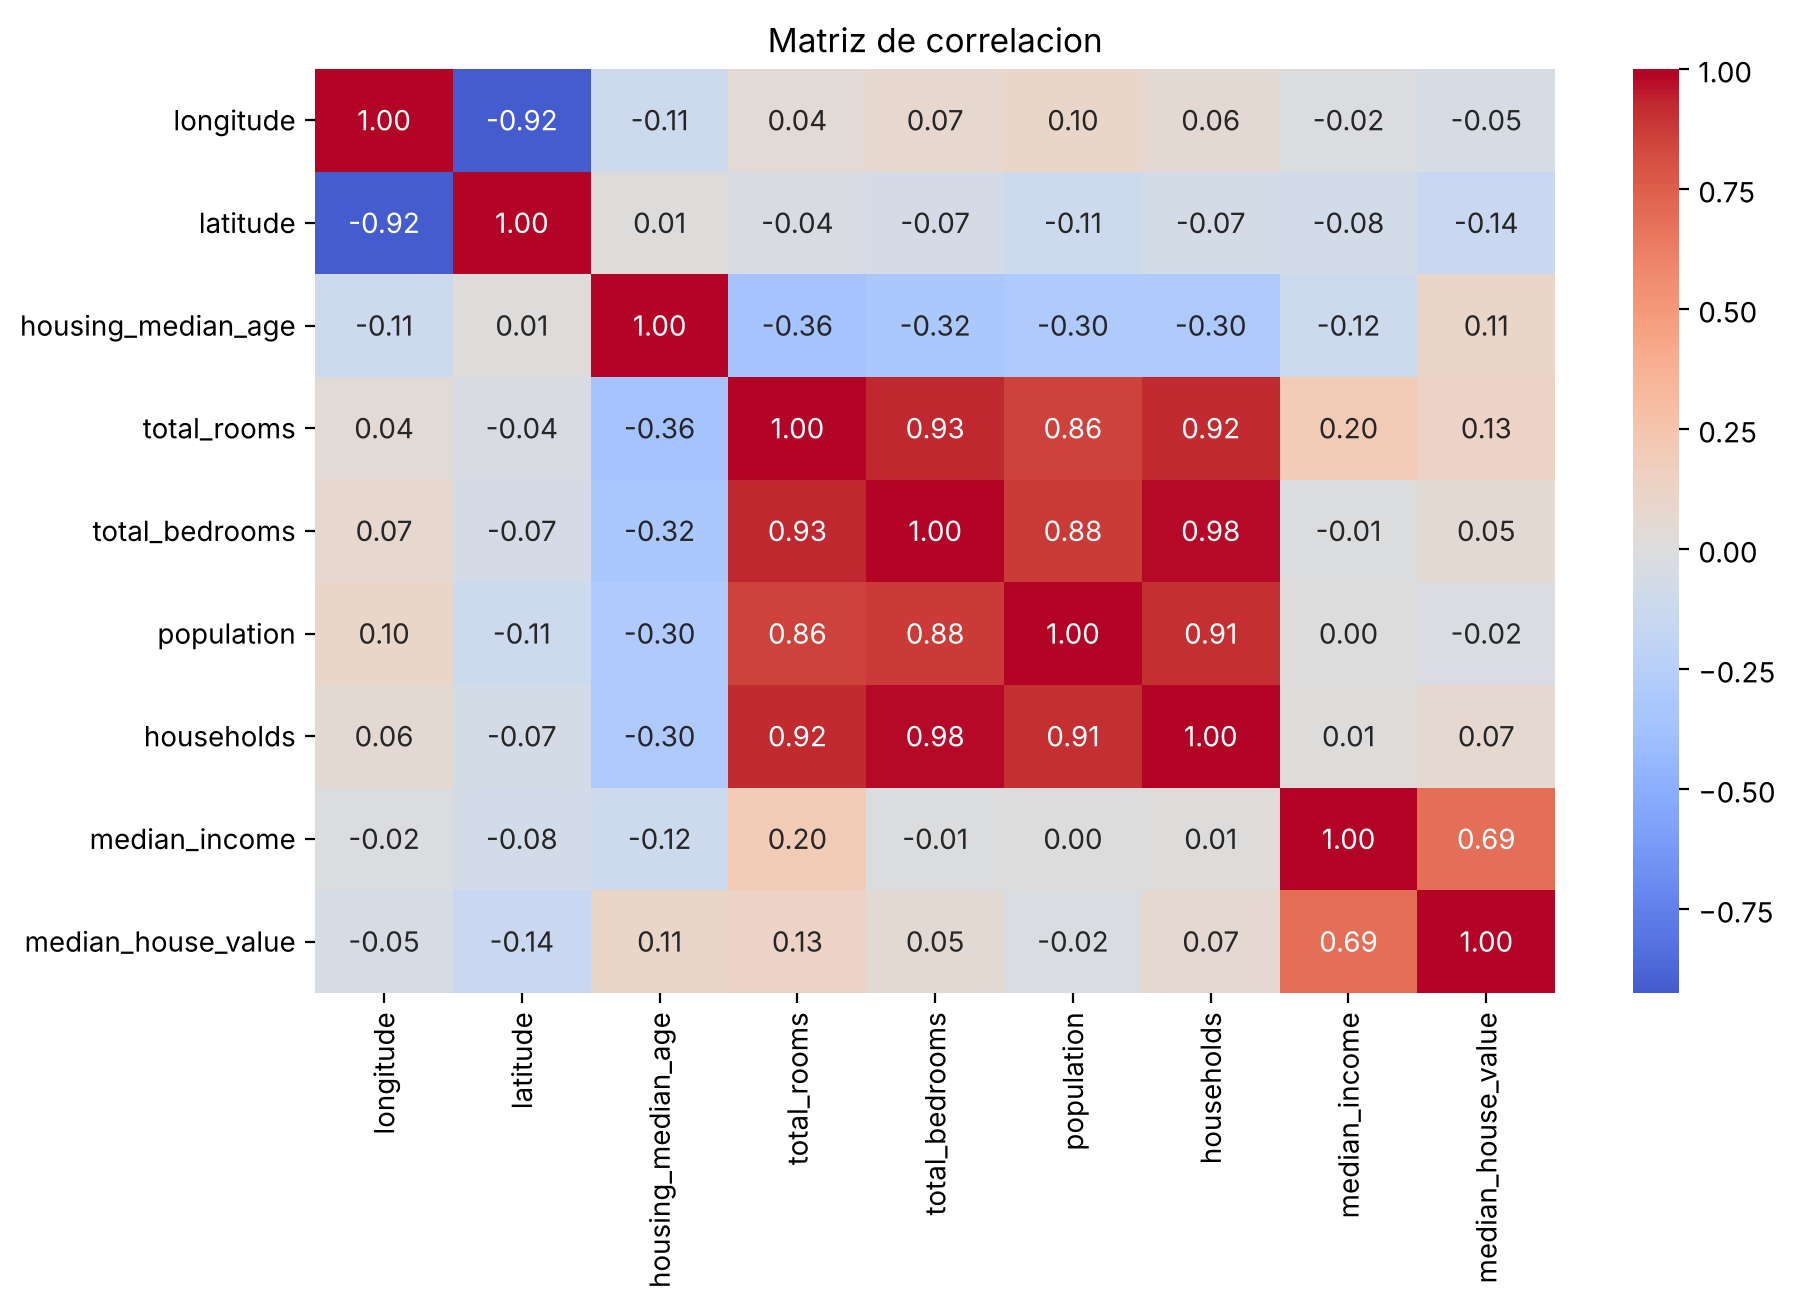

In [ ]:
# ocean_proximity es texto, por eso solo se usan las columnas numericas
corr_matrix = df.corr(numeric_only=True)

plt.figure(figsize=(10, 6))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matriz de correlacion")
plt.show()

La variable mas relacionada con el precio es median_income con 0.69, las demas tienen correlaciones bajas con el precio. Por otro lado total_rooms, total_bedrooms, population y households estan muy correlacionadas entre si, entre 0.86 y 0.98, y longitud con latitud tienen -0.92.

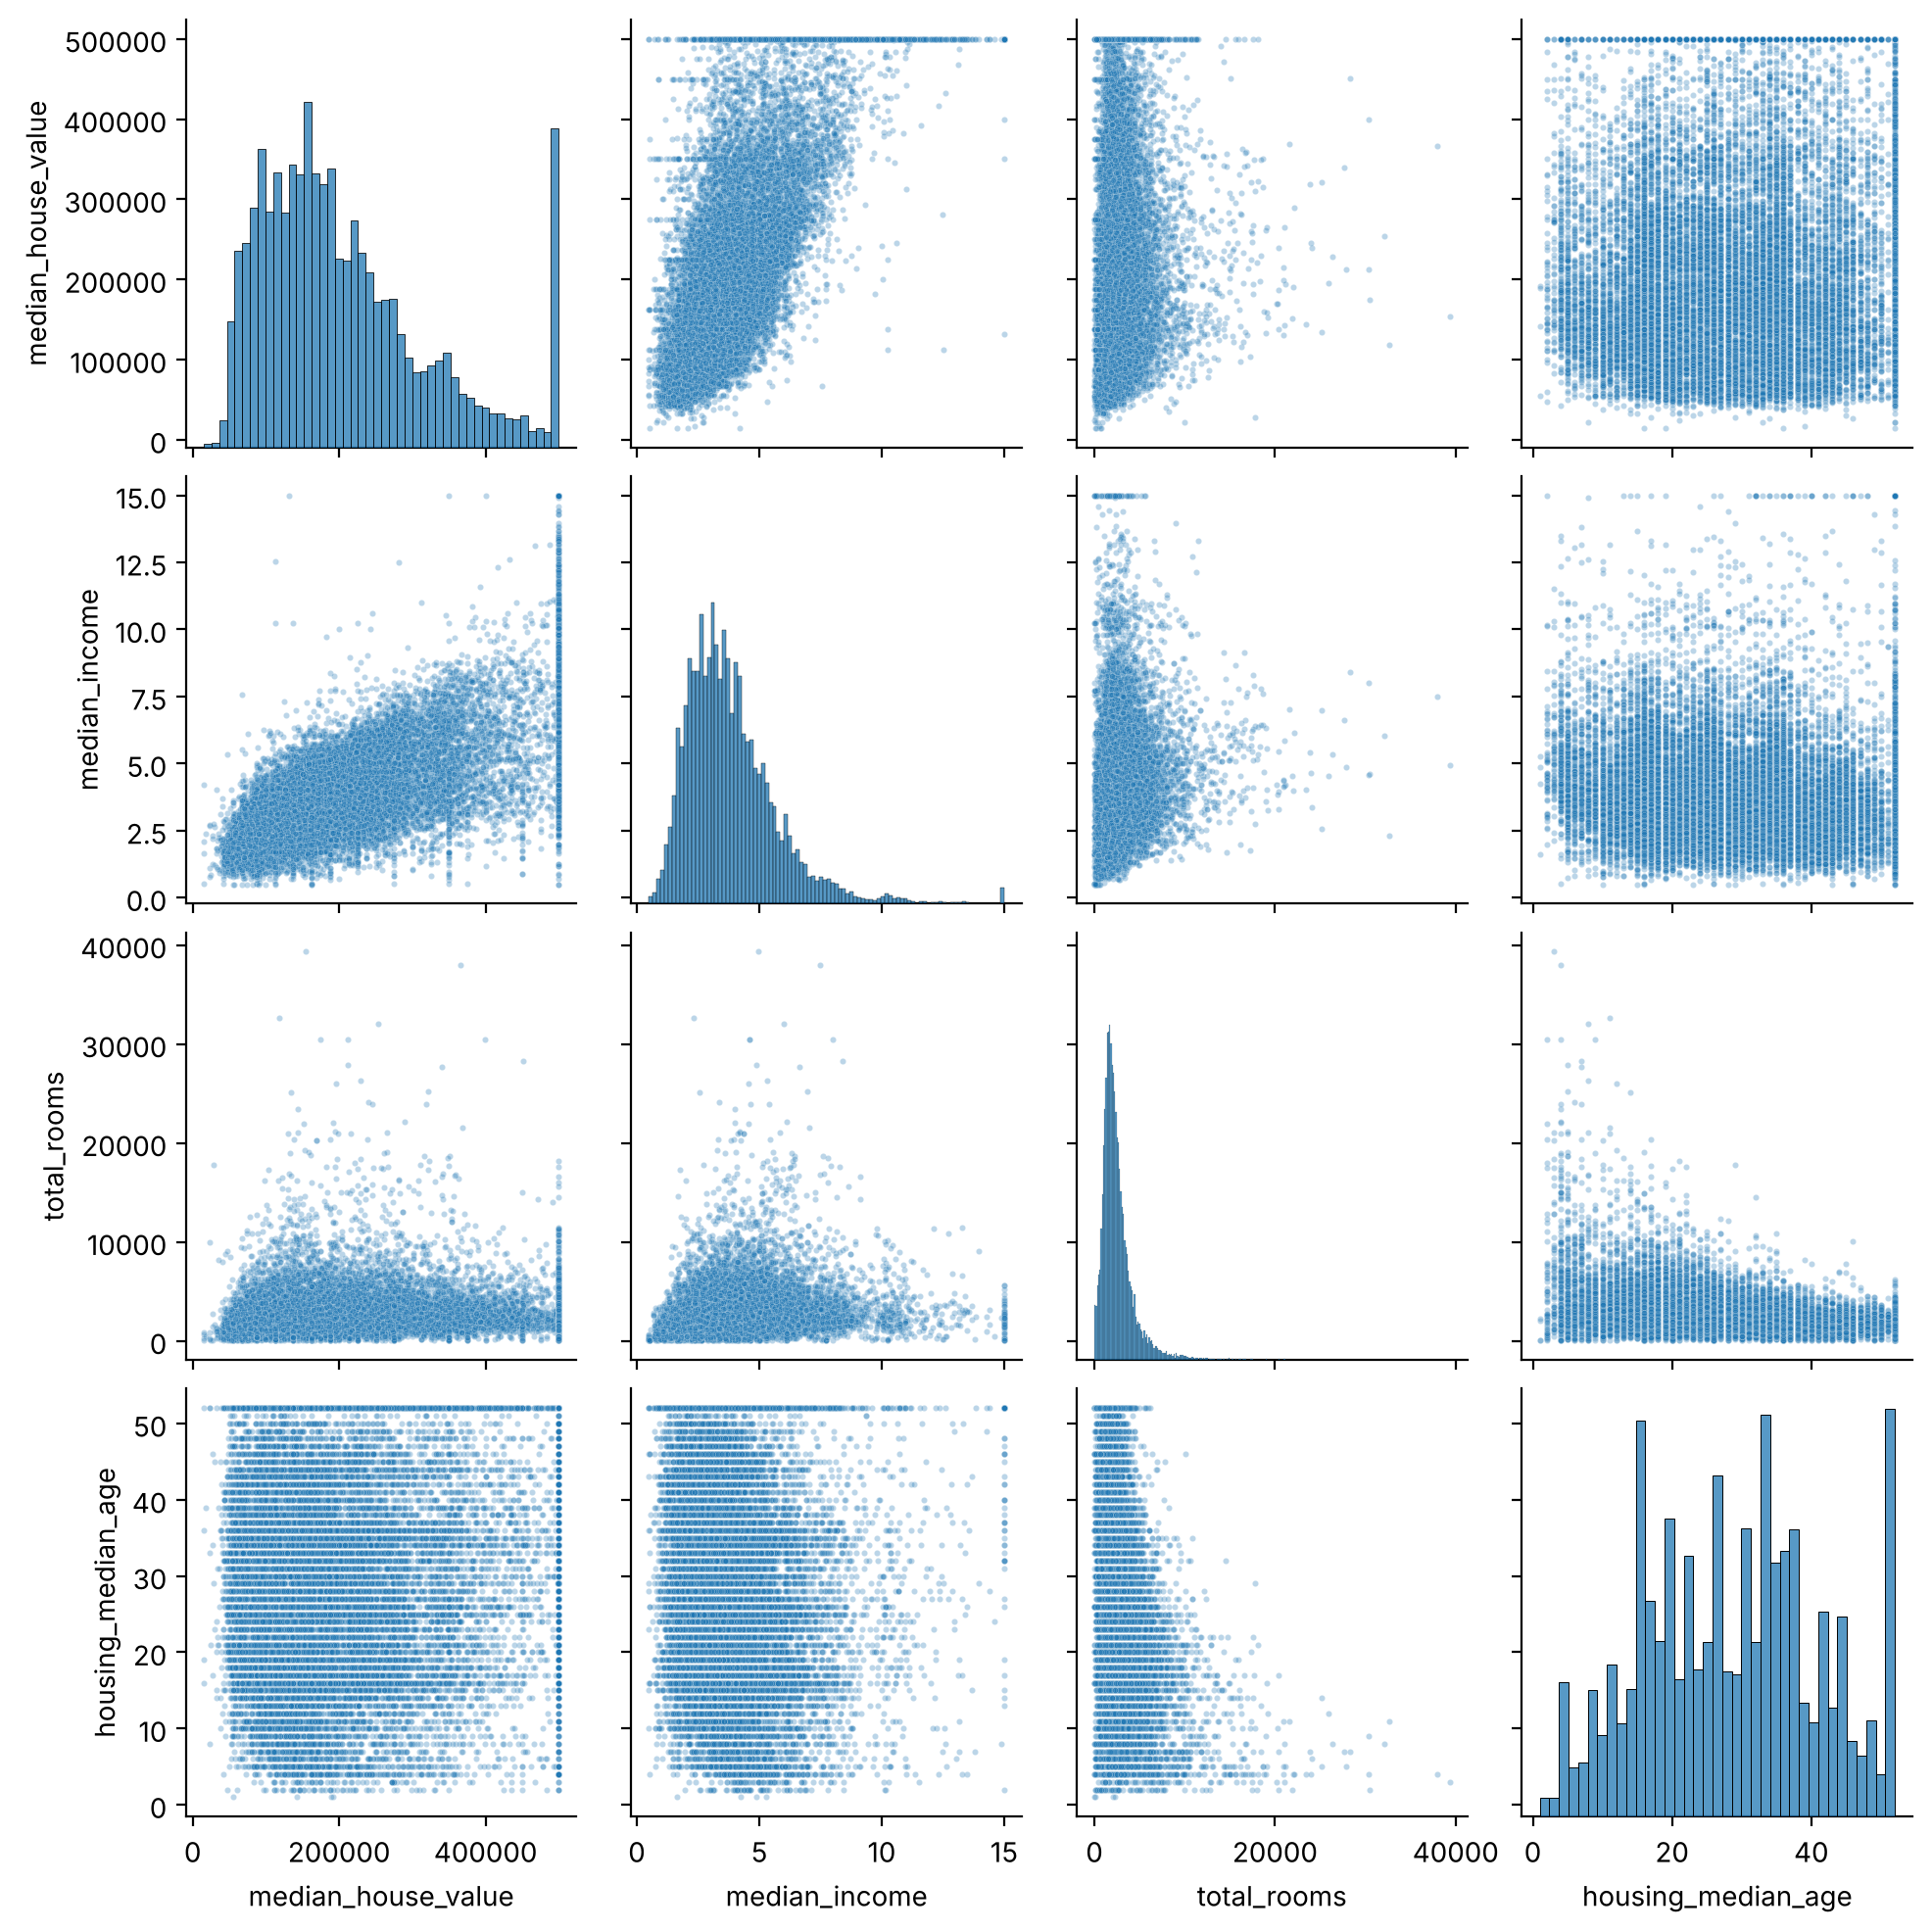

In [ ]:
cols = ["median_house_value", "median_income", "total_rooms", "housing_median_age"]
sns.pairplot(df[cols], plot_kws={"s": 5, "alpha": 0.3})
plt.show()

El unico panel donde se ve una tendencia clara con el precio es el de median_income, a mayor ingreso mayor valor de la vivienda, aunque con mucha dispersion. Tambien se nota una linea horizontal en 500000 que corresponde al recorte de los datos. Con total_rooms y housing_median_age no se ve una relacion clara.

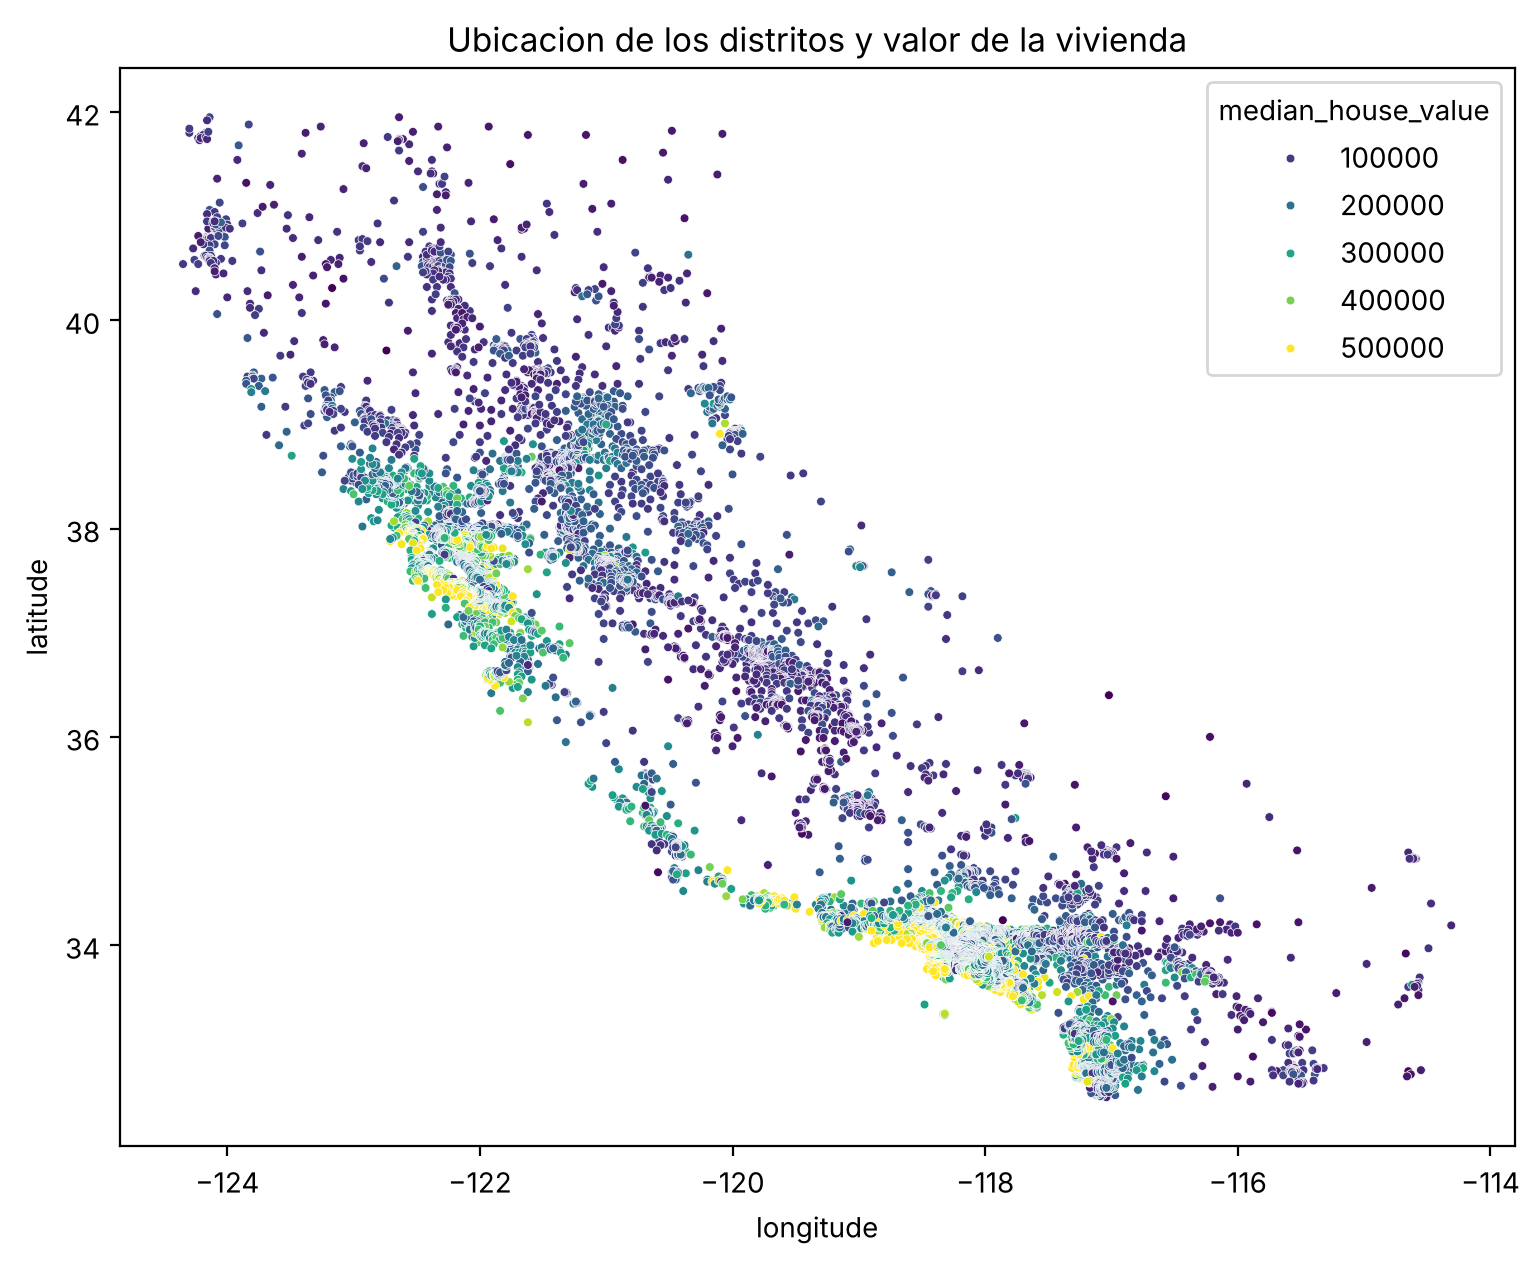

In [ ]:
plt.figure(figsize=(9, 7))
sns.scatterplot(data=df, x="longitude", y="latitude", hue="median_house_value", palette="viridis", s=10)
plt.title("Ubicacion de los distritos y valor de la vivienda")
plt.show()
#vemos el cambio de precio segun la posicion

Los puntos dibujan el mapa de California. Los distritos mas caros estan pegados a la costa y se agrupan en dos zonas, mientras que hacia el interior los valores son mas bajos.

## Analisis del bloque 1

Cada fila es un distrito de California y no una casa individual, por eso las variables son totales o medianas del distrito. Los datos estan casi completos, solo falta el 1% de total_bedrooms, pero tienen dos detalles que hay que tener en cuenta mas adelante. El primero es que el precio y la edad estan recortados en un valor maximo, entonces para los distritos mas caros no se conoce el valor real. El segundo es que las variables de conteo tienen colas muy largas y ademas estan muy correlacionadas entre si, como vimos anteriormente, lo que quiere decir que las cuatro cuentan practicamente lo mismo y es que tan grande es el distrito.

Lo que mas se relaciona con el precio es el ingreso y la ubicacion. El ingreso se ve directo en la matriz de correlacion, la ubicacion no aparece ahi porque la relacion no es una linea recta, pero en el mapa y en el boxplot se ve que estar cerca del mar sube aumenta el precio

# 2. Preparacion del data frame

In [ ]:
from sklearn.model_selection import train_test_split

train_set, test_set = train_test_split(df, test_size=0.2, random_state=42)

print(len(train_set))
print(len(test_set))

16512
4128


 Como el dataset es grande la division aleatoria no queda mal, se obtienen 16512 distritos para entrenar y 4128 para test. Pero el problema es que no garantiza que el test tenga las mismas proporciones que el dataset completo en las variables importantes, en este caso el ingreso. Eso se revisa en las siguientes celdas.

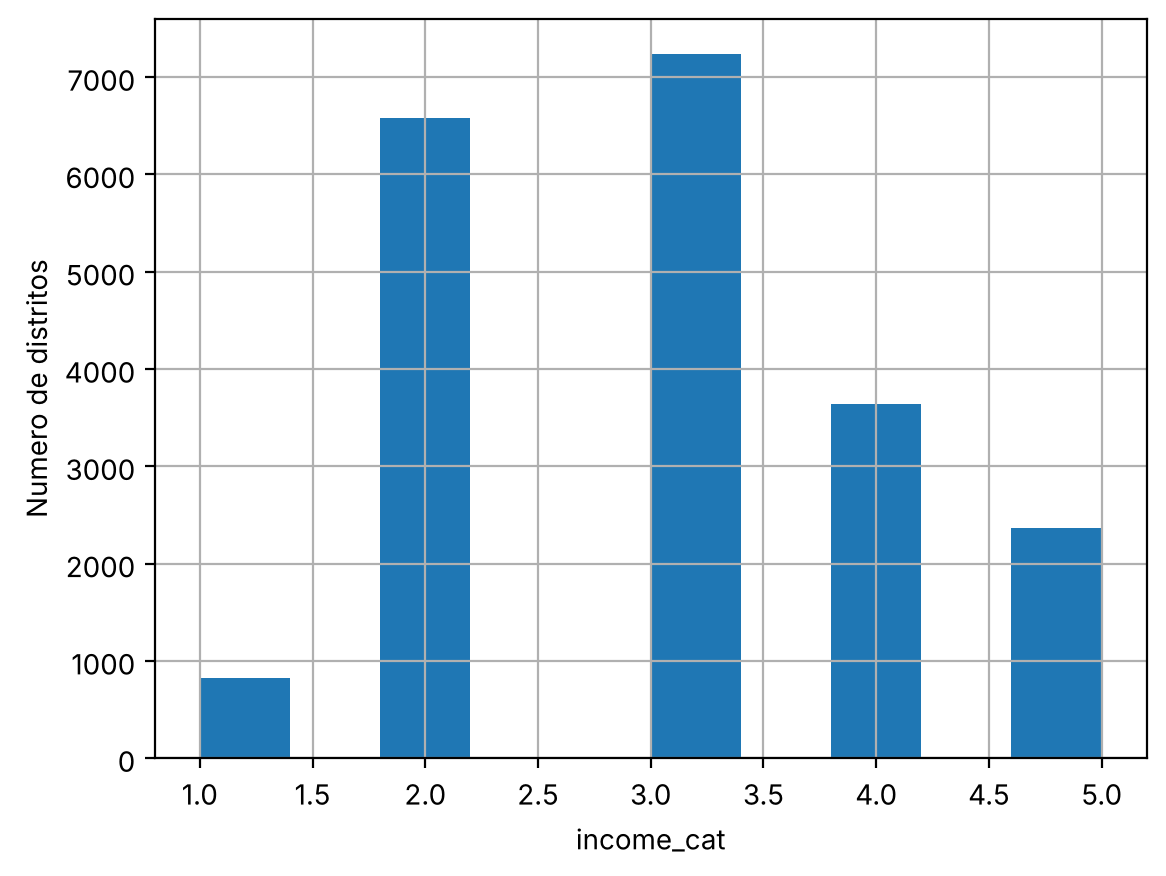

In [ ]:
# Se agrupa el ingreso en 5 categorias para poder estratificar
df["income_cat"] = pd.cut(df["median_income"],
                          bins=[0., 1.5, 3.0, 4.5, 6., np.inf],
                          labels=[1, 2, 3, 4, 5])

df["income_cat"].hist()
plt.xlabel("income_cat")
plt.ylabel("Numero de distritos")
plt.show()

In [ ]:
#Asi como antes
from sklearn.model_selection import StratifiedShuffleSplit

split = StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=42)

for train_index, test_index in split.split(df, df["income_cat"]):
    strat_train_set = df.loc[train_index]
    strat_test_set = df.loc[test_index]

print(len(strat_train_set))
print(len(strat_test_set))

16512
4128


In [ ]:
def income_cat_proportions(data):
    return data["income_cat"].value_counts() / len(data)

train_set, test_set = train_test_split(df, test_size=0.2, random_state=42)

compare_props = pd.DataFrame({
    "Overall": income_cat_proportions(df),
    "Stratified": income_cat_proportions(strat_test_set),
    "Random": income_cat_proportions(test_set),
}).sort_index()
compare_props["Rand. %error"] = abs(100 * compare_props["Random"] / compare_props["Overall"] - 100)
compare_props["Strat. %error"] = abs(100 * compare_props["Stratified"] / compare_props["Overall"] - 100)
compare_props.round(4)

,Overall,Stratified,Random,Rand. %error,Strat. %error
income_cat,,,,,
1,0.0398,0.0400,0.0402,0.9732,0.3650
2,0.3188,0.3188,0.3244,1.7323,0.0152
3,0.3506,0.3505,0.3585,2.2664,0.0138
4,0.1763,0.1764,0.1674,5.0563,0.0275
5,0.1144,0.1143,0.1095,4.3184,0.0847


Con la division estratificada las proporciones de cada categoria de ingreso en el test son casi identicas a las del dataset completo, el error mas grande es de 0.36%. Con la division aleatoria el error llega a 5% en la categoria 4 y a 4.3% en la categoria 5, es decir que el test aleatorio quedo con menos distritos de ingreso alto de los que deberia. Como el ingreso es la variable mas relacionada con el precio trabajamos con la division estratificada.

## Nuevas variables

In [ ]:
# Creamos una copia del conjunto de entrenamiento para no tocar el test
df_train = strat_train_set.copy()

df_train["rooms_per_household"] = df_train["total_rooms"] / df_train["households"]
df_train["bedrooms_per_room"] = df_train["total_bedrooms"] / df_train["total_rooms"]
df_train["population_per_household"] = df_train["population"] / df_train["households"]

# Correlacion de todas las variables con el precio
corr_train = df_train.corr(numeric_only=True)
print(corr_train["median_house_value"].sort_values(ascending=False).round(3))

median_house_value          1.000
median_income               0.687
rooms_per_household         0.146
total_rooms                 0.135
housing_median_age          0.114
households                  0.065
total_bedrooms              0.048
population_per_household   -0.022
population                 -0.027
longitude                  -0.047
latitude                   -0.143
bedrooms_per_room          -0.260
Name: median_house_value, dtype: float64


bedrooms_per_room tiene una correlacion de -0.26 con el precio, mas fuerte que total_rooms o total_bedrooms por separado. rooms_per_household tambien mejora un poco respecto a total_rooms. population_per_household practicamente no se relaciona con el precio.

## Limpieza de datos

In [ ]:
print(df_train.isnull().sum())

longitude                     0
latitude                      0
housing_median_age            0
total_rooms                   0
total_bedrooms              158
population                    0
households                    0
median_income                 0
median_house_value            0
ocean_proximity               0
income_cat                    0
rooms_per_household           0
bedrooms_per_room           158
population_per_household      0
dtype: int64


In [ ]:
# llenamos los faltantes de total_bedrooms con la mediana
median = df_train["total_bedrooms"].median()
q = df_train["total_bedrooms"].fillna(median).copy()
q = pd.DataFrame(q)

print(median)
print(q.isnull().sum())

433.0
total_bedrooms    0
dtype: int64


In [ ]:
from sklearn.impute import SimpleImputer

# El imputer solo funciona con columnas numericas y lo hace de forma automatica
df_train_num = df_train.drop(["ocean_proximity", "income_cat"], axis=1)

imp_mean = SimpleImputer(strategy="mean")
imp_mean.fit(df_train_num)

# Se compara lo que guarda el imputer con la mediana de cada columna
comparacion = pd.DataFrame({"imputer (media)": imp_mean.statistics_,
                            "mediana": df_train_num.median().values},
                           index=df_train_num.columns)
comparacion.round(2)

,imputer (media),mediana
longitude,-119.58,-118.51
latitude,35.64,34.26
housing_median_age,28.65,29.00
total_rooms,2622.54,2119.00
total_bedrooms,534.91,433.00
population,1419.69,1164.00
households,497.01,408.00
median_income,3.88,3.54
median_house_value,207005.32,179500.00
rooms_per_household,5.44,5.23


Lo que guarda el imputer en statistics es la media de cada columna porque se definio con strategy mean, por eso no coincide con la mediana. En las variables de conteo la media es bastante mayor que la mediana, por ejemplo 2623 contra 2119 en total_rooms, debido a las colas largas que se vieron en los histogramas. Por esa razon para llenar los faltantes de total_bedrooms prefiero la mediana, que no se deja arrastrar por los distritos enormes.

## Manejo de texto y atributos categoricos

In [ ]:
from sklearn.preprocessing import OneHotEncoder

housing_cat = df_train[["ocean_proximity"]]

cat_encoder = OneHotEncoder(sparse_output=False)
housing_cat_1hot = cat_encoder.fit_transform(housing_cat)

print(cat_encoder.categories_)
print(housing_cat_1hot[:5])

[array(['<1H OCEAN', 'INLAND', 'ISLAND', 'NEAR BAY', 'NEAR OCEAN'],
      dtype=object)]
[[0. 1. 0. 0. 0.]
 [0. 0. 0. 0. 1.]
 [0. 1. 0. 0. 0.]
 [0. 0. 0. 0. 1.]
 [1. 0. 0. 0. 0.]]


Estas lineas convierten la columna de texto ocean_proximity en cinco columnas de ceros y unos, una por cada categoria. En cada fila solo hay un 1, en la columna de la categoria a la que pertenece el distrito. Se hace asi porque el modelo solo recibe numeros y si se pusieran numeros del 1 al 5 el modelo entenderia que hay un orden entre las categorias que en realidad no existe.

## Data frame listo para el analisis

En la siguiente celda se juntan todos los pasos en orden. El imputer, el encoder y el scaler se ajustan unicamente con los datos de entrenamiento y despues se aplican al test, para que no se filtre informacion del test.

In [ ]:
from sklearn.preprocessing import MinMaxScaler

cols_num = ["longitude", "latitude", "housing_median_age", "total_rooms",
            "total_bedrooms", "population", "households", "median_income"]

# Se parte de la division estratificada y se reinicia el indice para poder unir tablas despues
train = strat_train_set.drop("income_cat", axis=1).reset_index(drop=True)
test = strat_test_set.drop("income_cat", axis=1).reset_index(drop=True)

# Etiquetas
y_train = train["median_house_value"]
y_test = test["median_house_value"]

# Limpieza, el imputer aprende la mediana solo con los datos de entrenamiento
imputer = SimpleImputer(strategy="median")
imputer.fit(train[cols_num])
num_train = pd.DataFrame(imputer.transform(train[cols_num]), columns=cols_num)
num_test = pd.DataFrame(imputer.transform(test[cols_num]), columns=cols_num)

# Atributo categorico
cat_encoder = OneHotEncoder(sparse_output=False)
cat_encoder.fit(train[["ocean_proximity"]])
cat_train = pd.DataFrame(cat_encoder.transform(train[["ocean_proximity"]]), columns=cat_encoder.categories_[0])
cat_test = pd.DataFrame(cat_encoder.transform(test[["ocean_proximity"]]), columns=cat_encoder.categories_[0])

# Se unen las numericas con las categoricas
housing_tr_train = num_train.join(cat_train)
housing_tr_test = num_test.join(cat_test)

# Escalamiento, el scaler tambien se ajusta solo con entrenamiento
scaler = MinMaxScaler()
scaler.fit(housing_tr_train)
X_train = pd.DataFrame(scaler.transform(housing_tr_train), columns=housing_tr_train.columns)
X_test = pd.DataFrame(scaler.transform(housing_tr_test), columns=housing_tr_test.columns)

# Data frames finales con caracteristicas y etiqueta
housing_train = X_train.copy()
housing_train["median_house_value"] = y_train
housing_test = X_test.copy()
housing_test["median_house_value"] = y_test

print(housing_train.shape)
print(housing_test.shape)
print(housing_train.isnull().sum().sum()) # no deben quedar faltantes
housing_train.head()

(16512, 14)
(4128, 14)
0


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,<1H OCEAN,INLAND,ISLAND,NEAR BAY,NEAR OCEAN,median_house_value
0,0.287849,0.635494,0.549020,0.098362,0.128061,0.062614,0.131441,0.115426,0.0,1.0,0.0,0.0,0.0,72100.0
1,0.709163,0.058448,0.117647,0.135168,0.137403,0.056392,0.143017,0.402574,0.0,0.0,0.0,0.0,1.0,279600.0
2,0.528884,0.300744,0.843137,0.041003,0.049613,0.018610,0.055639,0.163798,0.0,1.0,0.0,0.0,0.0,82700.0
3,0.719124,0.022317,0.450980,0.047591,0.083280,0.025085,0.089806,0.119067,0.0,0.0,0.0,0.0,1.0,112500.0
4,0.562749,0.184910,0.509804,0.089790,0.103737,0.051403,0.107916,0.275617,1.0,0.0,0.0,0.0,0.0,238300.0


## Analisis

Quedan dos data frames, housing_train con 16512 distritos y housing_test con 4128, cada uno con 13 caracteristicas escaladas entre 0 y 1 y la etiqueta median_house_value. La division se hizo estratificando por ingreso porque es la variable que mas pesa sobre el precio y la division aleatoria dejaba errores de hasta 5% en las proporciones. Los faltantes se llenaron con la mediana y la variable categorica se paso a cinco columnas de ceros y unos.

Las variables nuevas no se incluyeron en estos data frames y se dejaron las mismas 13 columnas que propone el enunciado que se retomaran en el bloque de PCA.

# Regresion lineal

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train)

pred_train = lin_reg.predict(X_train)
pred_test = lin_reg.predict(X_test)

# El score de una regresion es el R2
print("R2 entrenamiento", round(lin_reg.score(X_train, y_train), 3))
print("R2 test", round(lin_reg.score(X_test, y_test), 3))

rmse_train = np.sqrt(mean_squared_error(y_train, pred_train))
rmse_test = np.sqrt(mean_squared_error(y_test, pred_test))
print("RMSE entrenamiento", round(rmse_train))
print("RMSE test", round(rmse_test))
print("Predicciones negativas en test", np.sum(pred_test < 0))

R2 entrenamiento 0.644
R2 test 0.652
RMSE entrenamiento 69051
RMSE test 67347
Predicciones negativas en test 13


In [ ]:
coef_lin = pd.Series(lin_reg.coef_, index=X_train.columns)
print(coef_lin.round(0))
print("Intercepto", round(lin_reg.intercept_))

longitude             -266620.0
latitude              -237756.0
housing_median_age      55661.0
total_rooms           -184259.0
total_bedrooms         452428.0
population           -1401276.0
households             412021.0
median_income          561301.0
<1H OCEAN              -18139.0
INLAND                 -57836.0
ISLAND                 112926.0
NEAR BAY               -22518.0
NEAR OCEAN             -14433.0
dtype: float64
Intercepto 273079


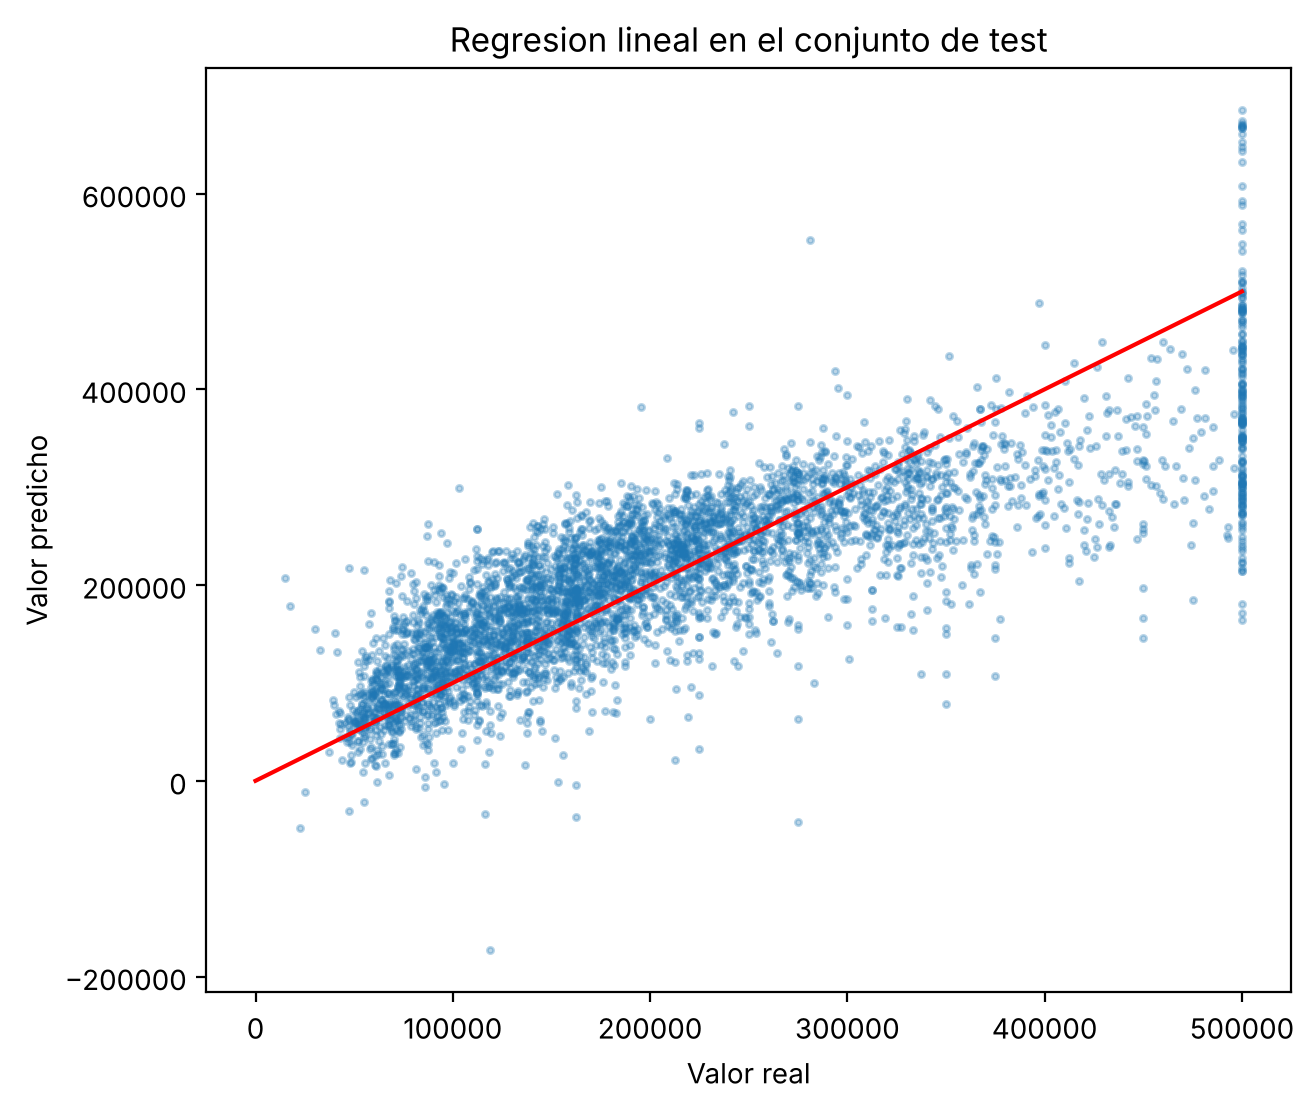

In [ ]:
plt.figure(figsize=(7, 6))
plt.scatter(y_test, pred_test, s=5, alpha=0.3)
plt.plot([0, 500000], [0, 500000], color="red") # linea de prediccion perfecta
plt.xlabel("Valor real")
plt.ylabel("Valor predicho")
plt.title("Regresion lineal en el conjunto de test")
plt.show()

Si el modelo fuera perfecto los puntos estarian sobre la linea roja. La nube sigue la tendencia pero se desvia entorno a la linea, y a la derecha se ve una columna vertical de puntos justo en 500000 que son los distritos con el precio recortado, que hablamos anteriorement, ahi el modelo predice valores muy distintos para un mismo valor real.

## Automatizacion con pipelines

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

# Pasos para las columnas numericas
num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", MinMaxScaler()),
])

# Cada tipo de columna recibe su tratamiento
preparacion = ColumnTransformer([
    ("num", num_pipeline, cols_num),
    ("cat", OneHotEncoder(), ["ocean_proximity"]),
])

# Preparacion y modelo en un solo objeto
modelo_lineal = Pipeline([
    ("preparacion", preparacion),
    ("regresion", LinearRegression()),
])

# Ahora se le pasan los datos crudos
modelo_lineal.fit(train, y_train)

print("R2 entrenamiento", round(modelo_lineal.score(train, y_train), 3))
print("R2 test", round(modelo_lineal.score(test, y_test), 3))

R2 entrenamiento 0.644
R2 test 0.652


## Analisis de la regresion lineal

1. El modelo explica cerca del 65% de la variacion del precio y se equivoca en promedio unos 67000 dolares, que es bastante si se compara con la mediana del precio que es de 179500. El error en test es practicamente igual al de entrenamiento, asi que no hay sobreajuste, mas bien al modelo le falta flexibilidad.

2. Es valido como primer modelo pero con limitaciones. En la grafica se ve que no puede manejar los distritos recortados en 500001, en test hay 13 predicciones negativas que no tienen sentido para un precio, y los coeficientes de total_rooms, total_bedrooms, population y households son enormes y con signos opuestos, lo que es consecuencia de que esas cuatro variables estan muy correlacionadas. Entonces el modelo sirve para predecir de forma aproximada, pero sus coeficientes no se pueden leer uno por uno.

3. El score es el R2, dice que fraccion de la variabilidad del precio logra explicar el modelo. Un valor de 1 seria una prediccion perfecta y un valor de 0 seria igual a predecir siempre el promedio. Aqui es 0.644 en entrenamiento y 0.652 en test.

4. Si, se puede ajustar a otros modelos y eso se hace en los bloques 3 y 4, primero con un modelo mas simple y despues con modelos mas complejos y regularizados para ver como varian unos respecto otros

5. Con Pipelines se hace como en la celda anterior. Los pasos de imputar, escalar y codificar se guardan junto con el modelo en un solo objeto, se ajusta con los datos crudos y da el mismo score que el procedimiento manual.

# 3. Modelo base interpretable con PCA

     varianza  acumulada
PC1     0.488      0.488
PC2     0.238      0.726
PC3     0.134      0.859
PC4     0.103      0.963
PC5     0.019      0.982
PC6     0.010      0.992
PC7     0.006      0.998
PC8     0.002      1.000


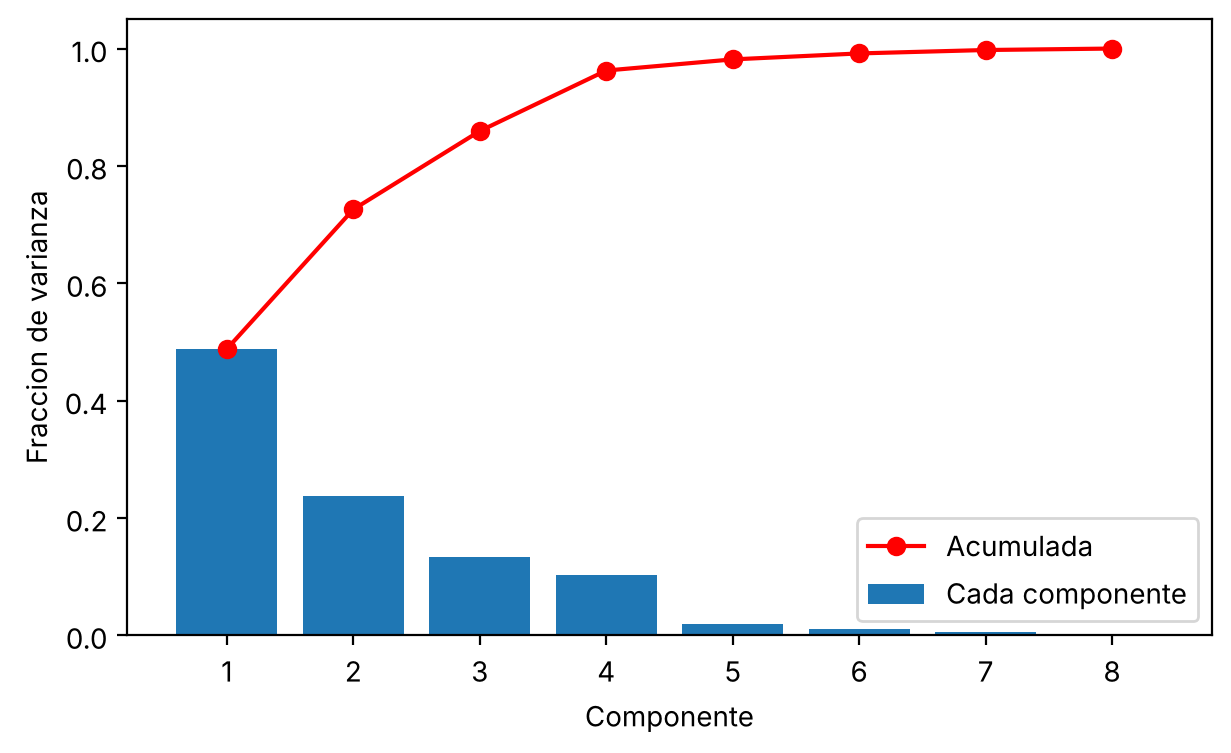

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Mismas variables numericas del bloque anterior, ya sin faltantes
std_scaler = StandardScaler()
std_scaler.fit(num_train)
Z_train = std_scaler.transform(num_train)
Z_test = std_scaler.transform(num_test)

pca = PCA()
pca.fit(Z_train)

varianza = pca.explained_variance_ratio_
varianza_acumulada = np.cumsum(varianza)

tabla_varianza = pd.DataFrame({"varianza": varianza, "acumulada": varianza_acumulada},
                              index=["PC1", "PC2", "PC3", "PC4", "PC5", "PC6", "PC7", "PC8"])
print(tabla_varianza.round(3))

plt.figure(figsize=(7, 4))
plt.bar(range(1, 9), varianza, label="Cada componente")
plt.plot(range(1, 9), varianza_acumulada, color="red", marker="o", label="Acumulada")
plt.xlabel("Componente")
plt.ylabel("Fraccion de varianza")
plt.legend()
plt.show()

Las primeras cuatro componentes acumulan el 96% de la varianza y de la quinta en adelante cada una aporta menos del 2%. Asi que nos quedamos con cuatro componentes, es decir que se pasamos de 8 variables numericas a 4.

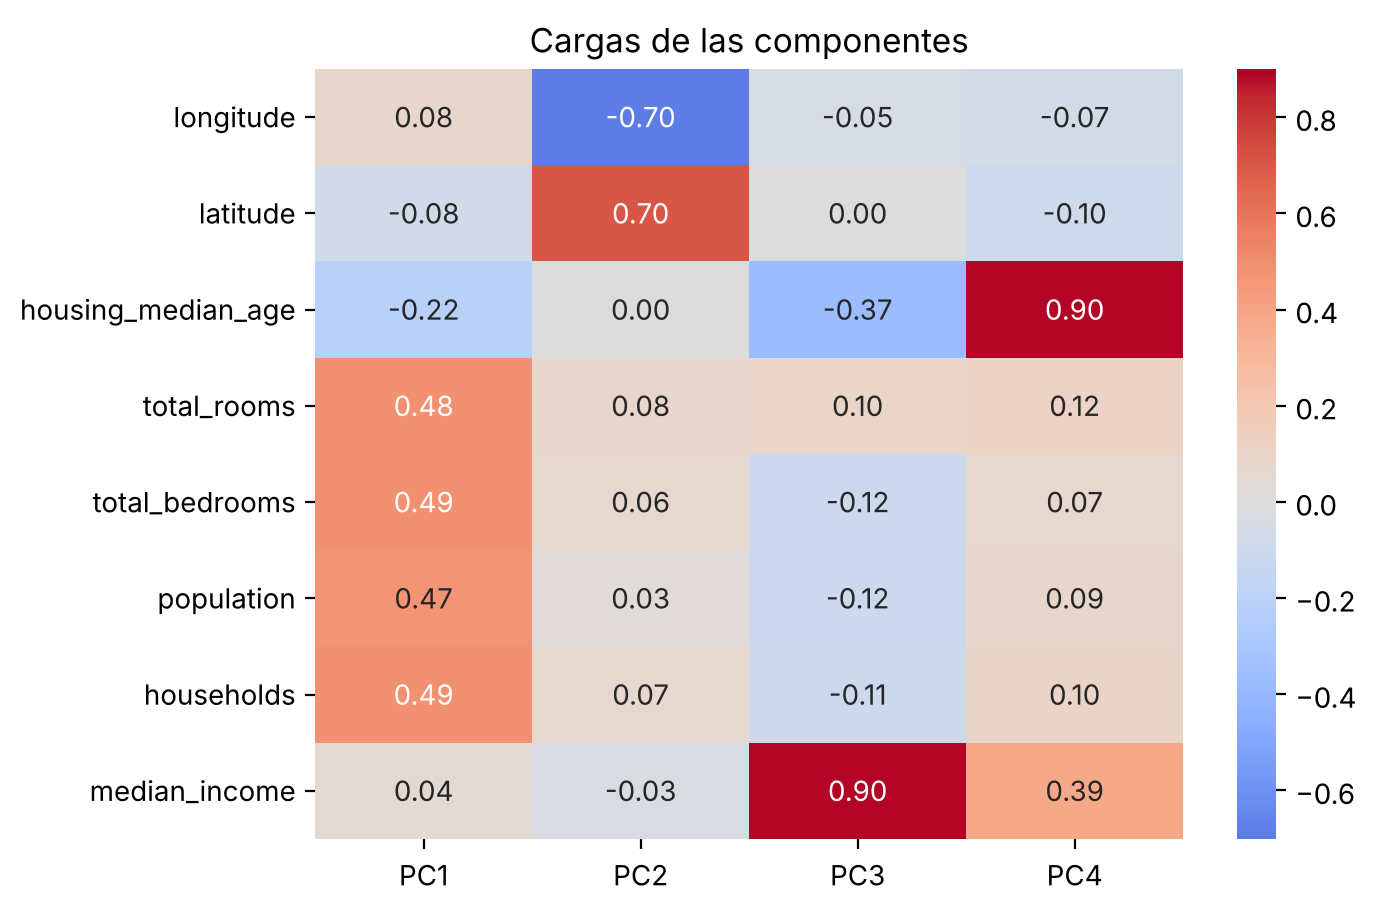

In [ ]:
n_comp = 4

# Cargas, cuanto pesa cada variable original en cada componente
cargas = pd.DataFrame(pca.components_[:n_comp].T, index=cols_num, columns=["PC1", "PC2", "PC3", "PC4"])

plt.figure(figsize=(7, 5))
sns.heatmap(cargas, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Cargas de las componentes")
plt.show()

PC1 esta formada casi por partes iguales por total_rooms, total_bedrooms, population y households, que es justo el grupo de variables que en la matriz de correlacion tenia valores entre 0.86 y 0.98, se puede interpretar como el tamaño del distrito. PC2 es longitud contra latitud, que tenian correlacion de -0.92, y representa la ubicacion a lo largo del estado. PC3 es sobre todo el ingreso y PC4 es sobre todo la edad de las viviendas, las dos variables que en el pairplot no se parecian con ninguna de las demas

In [ ]:
pca4 = PCA(n_components=n_comp)
pca4.fit(Z_train)
T_train = pca4.transform(Z_train)
T_test = pca4.transform(Z_test)

modelo_pca = LinearRegression()
modelo_pca.fit(T_train, y_train)

print("Modelo reducido  R2 entrenamiento", round(modelo_pca.score(T_train, y_train), 3))
print("Modelo reducido  R2 test", round(modelo_pca.score(T_test, y_test), 3))
print("Regresion lineal R2 entrenamiento", round(lin_reg.score(X_train, y_train), 3))
print("Regresion lineal R2 test", round(lin_reg.score(X_test, y_test), 3))

Modelo reducido  R2 entrenamiento 0.524
Modelo reducido  R2 test 0.522
Regresion lineal R2 entrenamiento 0.644
Regresion lineal R2 test 0.652


Con solo cuatro variables el R2 baja de 0.644 a 0.524 en entrenamiento y de 0.652 a 0.522 en test, se pierde 0.13 . Hay que aclarar que la regresion original tambien usa las cinco columnas de ocean_proximity y el modelo reducido no la utiliza, por tanto no toda la perdida se debe a resumir las variables numericas reducidas.

In [ ]:
# Variables nuevas calculadas con los datos de entrenamiento ya limpios
nuevas = pd.DataFrame()
nuevas["rooms_per_household"] = num_train["total_rooms"] / num_train["households"]
nuevas["bedrooms_per_room"] = num_train["total_bedrooms"] / num_train["total_rooms"]
nuevas["population_per_household"] = num_train["population"] / num_train["households"]

# Para cada variable nueva se mira que tanto la explican las 4 componentes
for col in nuevas.columns:
    reg = LinearRegression()
    reg.fit(T_train, nuevas[col])
    print(col, " R2 explicado por las componentes", round(reg.score(T_train, nuevas[col]), 3))

# Modelo reducido agregando las variables nuevas
T_nuevas = np.hstack([T_train, nuevas.values])
modelo_pca_nuevas = LinearRegression()
modelo_pca_nuevas.fit(T_nuevas, y_train)
print("R2 entrenamiento con componentes y variables nuevas", round(modelo_pca_nuevas.score(T_nuevas, y_train), 3))

rooms_per_household  R2 explicado por las componentes 0.131
bedrooms_per_room  R2 explicado por las componentes 0.332
population_per_household  R2 explicado por las componentes 0.001
R2 entrenamiento con componentes y variables nuevas 0.55


Las cuatro componentes explican muy poco de las variables nuevas, 13% de rooms_per_household, 33% de bedrooms_per_room y casi nada de population_per_household. Tiene sentido porque las componentes son sumas de las variables originales y las nuevas son las divisiones, eso no lo puede reproducir con PCA. Al agregarlas al modelo reducido el R2 de entrenamiento sube de 0.524 a 0.55, entonces si aportan algo de informacion que las componentes no se capturan, aunque el aporte es pequeño.

In [ ]:
#  Escalemos con MinMaxScaler
mm_scaler = MinMaxScaler()
mm_scaler.fit(num_train)
M_train = mm_scaler.transform(num_train)

pca_mm = PCA()
pca_mm.fit(M_train)

print("Varianza por componente con StandardScaler")
print(pca.explained_variance_ratio_.round(3))
print("Varianza por componente con MinMaxScaler")
print(pca_mm.explained_variance_ratio_.round(3))

# Varianza de cada variable despues de MinMaxScaler
print(pd.Series(M_train.var(axis=0), index=cols_num).round(4))

cargas_mm = pd.DataFrame(pca_mm.components_[:2].T, index=cols_num, columns=["PC1", "PC2"])
print(cargas_mm.round(2))

Varianza por componente con StandardScaler
[0.488 0.238 0.134 0.103 0.019 0.01  0.006 0.002]
Varianza por componente con MinMaxScaler
[0.486 0.341 0.095 0.06  0.015 0.001 0.001 0.   ]
longitude             0.0398
latitude              0.0516
housing_median_age    0.0608
total_rooms           0.0030
total_bedrooms        0.0044
population            0.0010
households            0.0049
median_income         0.0173
dtype: float64
                     PC1   PC2
longitude          -0.65  0.06
latitude            0.74 -0.16
housing_median_age  0.15  0.97
total_rooms        -0.02 -0.09
total_bedrooms     -0.03 -0.10
population         -0.02 -0.04
households         -0.03 -0.10
median_income      -0.03 -0.07


Para PCA MinMaxScaler no es la eleccion adecuada. PCA busca las direcciones con mas varianza, y despues de MinMaxScaler las variables no quedan con la misma varianza. Las de conteo quedan reducidas cerca de cero por culpa de los valores extremos, population queda con varianza 0.001 mientras que la edad queda con 0.061. El resultado es que las dos primeras componentes con MinMaxScaler son casi solo latitud, longitud y edad, y el grupo de variables de tamaño practicamente desaparece. Con StandardScaler todas las variables quedan con varianza 1 y las componentes reflejan las correlaciones entre variables.

R2 real 0.524
R2 maximo con el precio desordenado 0.00108
Permutaciones que igualan o superan el R2 real 0


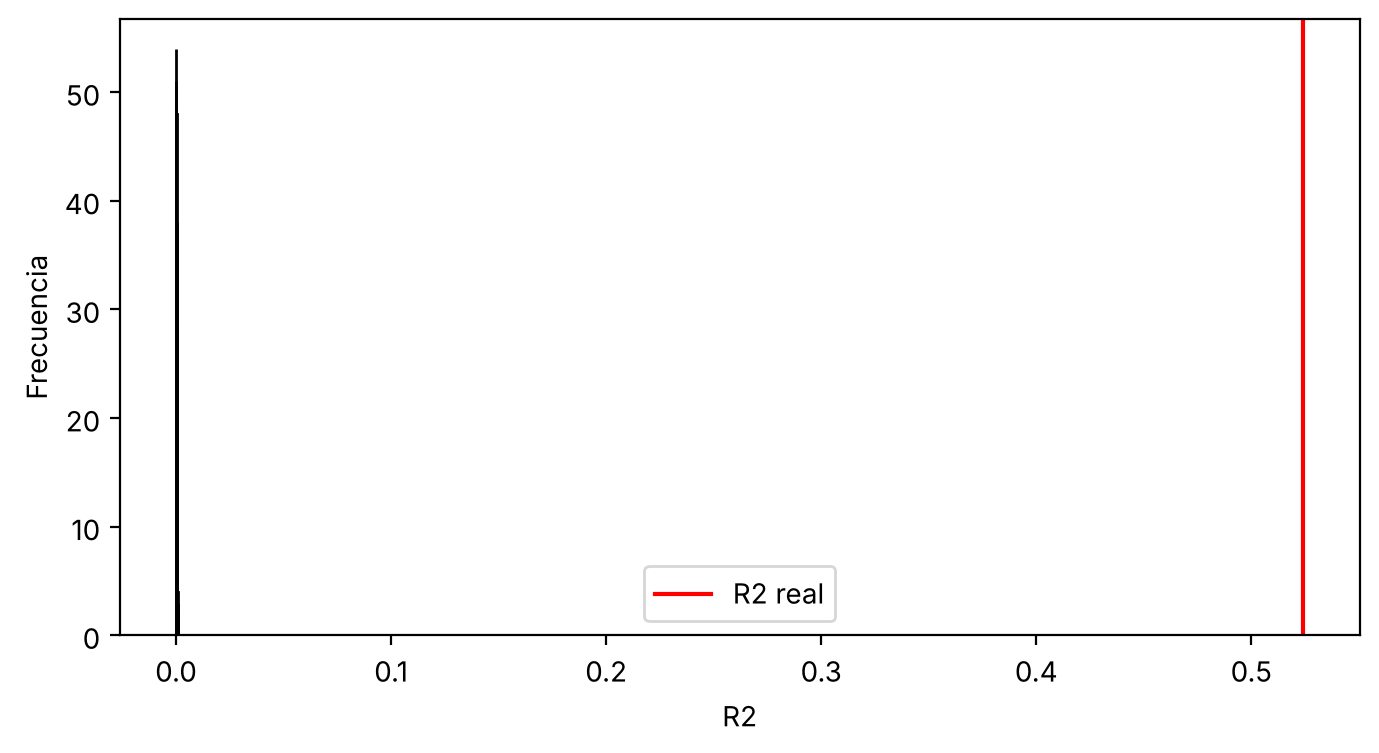

In [ ]:
# Test de permutaciones, se desordena el precio y se vuelve a ajustar el modelo reducido
np.random.seed(42)
r2_real = modelo_pca.score(T_train, y_train)

r2_permutados = []
for i in range(500):
    y_desordenado = np.random.permutation(y_train)
    reg = LinearRegression()
    reg.fit(T_train, y_desordenado)
    r2_permutados.append(reg.score(T_train, y_desordenado))

r2_permutados = np.array(r2_permutados)
print("R2 real", round(r2_real, 3))
print("R2 maximo con el precio desordenado", round(r2_permutados.max(), 5))
print("Permutaciones que igualan o superan el R2 real", np.sum(r2_permutados >= r2_real))

plt.figure(figsize=(8, 4))
plt.hist(r2_permutados, bins=30, color="steelblue", edgecolor="black")
plt.axvline(r2_real, color="red", label="R2 real")
plt.xlabel("R2")
plt.ylabel("Frecuencia")
plt.legend()
plt.show()

Al desordenar el precio se rompen las rela iones reales. En 500 permutaciones el R2 nunca paso de 0.001, mientras que el modelo reducido tiene 0.524. Ninguna permutacion se acerca al valor real, asi que el modelo reducido si esta capturando algo real y no es un resultado dele azr

PC1     3558.0
PC2    -4056.0
PC3    63054.0
PC4    57070.0
dtype: float64


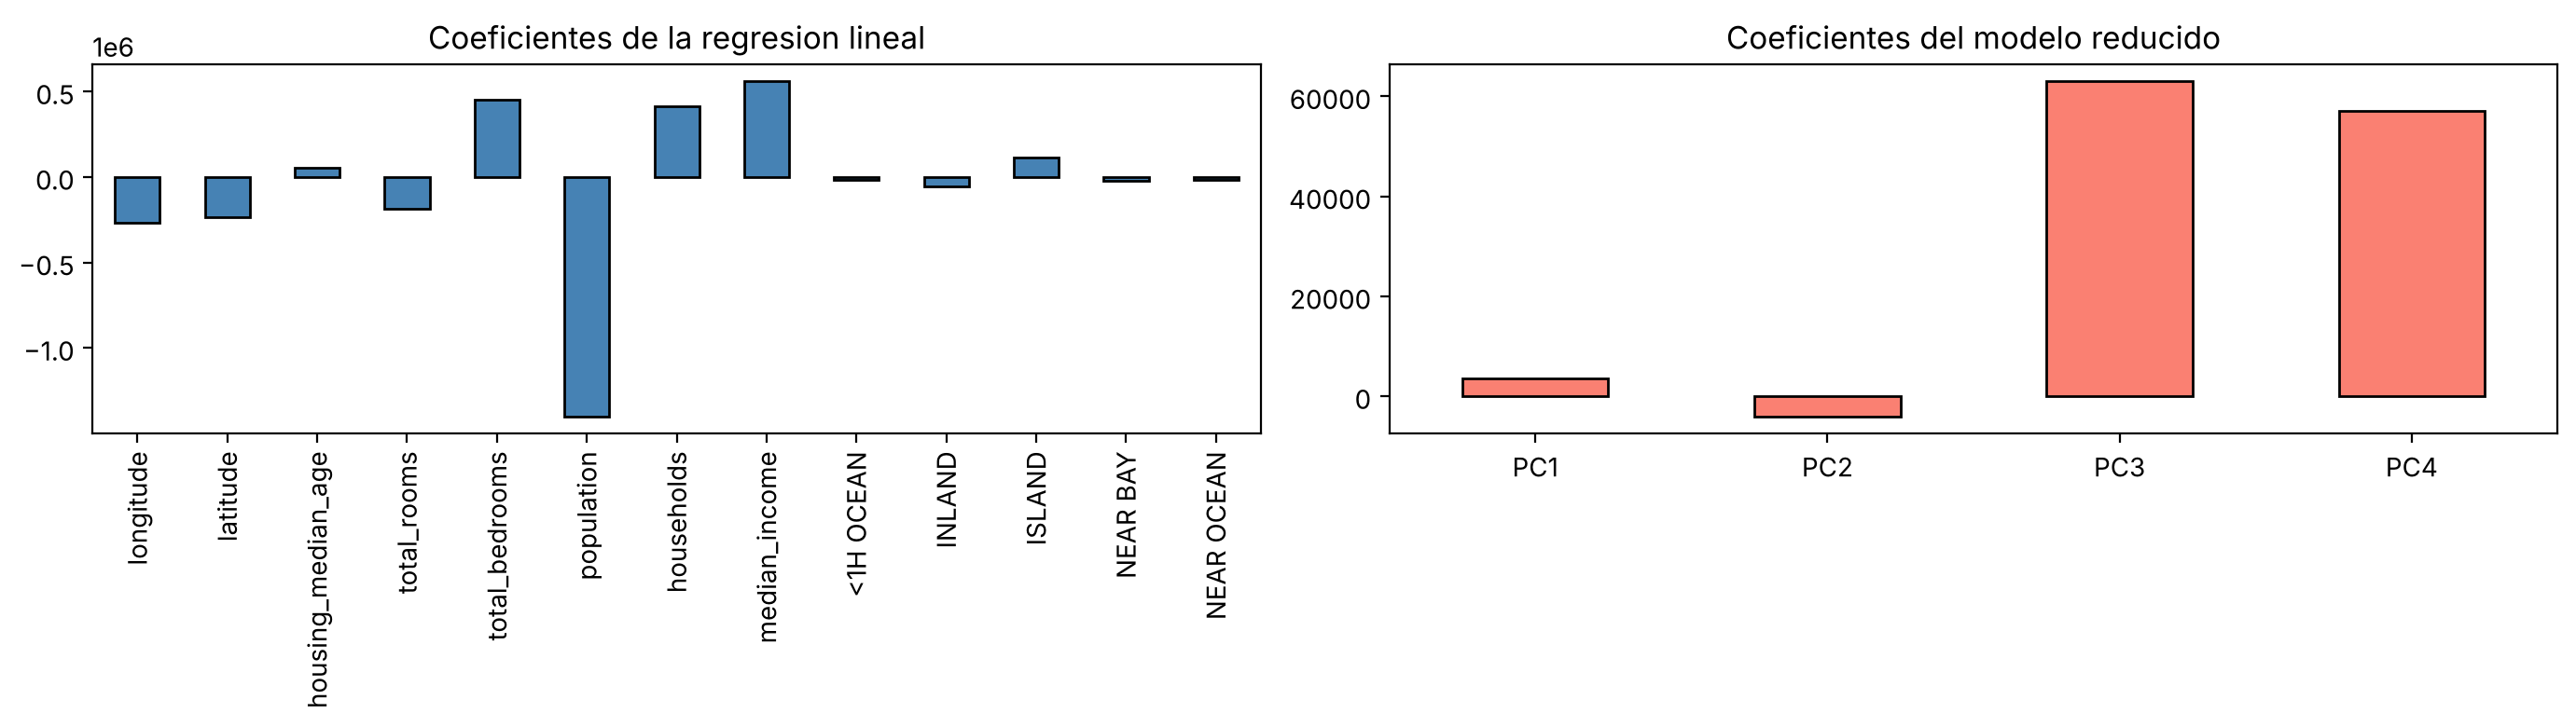

In [ ]:
coef_pca = pd.Series(modelo_pca.coef_, index=["PC1", "PC2", "PC3", "PC4"])
print(coef_pca.round(0))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
coef_lin.plot(kind="bar", ax=axes[0], color="steelblue", edgecolor="black")
axes[0].set_title("Coeficientes de la regresion lineal")
coef_pca.plot(kind="bar", ax=axes[1], color="salmon", edgecolor="black")
axes[1].set_title("Coeficientes del modelo reducido")
axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

## Analisis

El modelo reducido usa cuatro variables que se pueden nombrar como tamaño del distrito, ubicacion, ingreso y edad de las viviendas. A cambio se pierden cerca de 0.13 puntos de R2 frente a la regresion de 13 variables, y el test de permutaciones muestra que esta infromacion es

Al comparar los coeficientes el modelo reducido es mas facil de interpretar. En la regresion original los coeficientes muy granndes y de signos contrarios, por ejemplo population tiene -1401276 y total_bedrooms 452428, y eso no significa que mas poblacion baje el precio en esa cantidad, es que el modelo reparte de forma arbitraria el efecto entre variables que dicen lo mismo. En el modelo reducido las componentes no estan correlacionadas entre si, entonces cada coeficiente se puede leer por separado. Los coeficientes grandes son los de PC3 y PC4, que son ingreso y edad, mientras que PC1 y PC2 pesan muy poco. Es decir que la componente que mas varianza tiene, el tamaño del distrito, casi no sirve para predecir el precio. PCA ordena las componentes por varianza sin mirar el precio, y eso es una limitacion importante para construir el modelo.

Sobre el escalamiento, para PCA cambiamos MinMaxScaler por StandardScaler por lo que se mostro arriba. Las variables nuevas aportan un poco de informacion adicional.

# 4. Regularizacion L2 vs L1

Para responder con evidencia si la regresion se puede ajustar a otro modelo, se toma la regresion lineal de las 13 variables y se le agregan terminos polinomiales, que son potencias y productos entre las variables. Para escoger entre modelos se separa una parte del entrenamiento como validacion.

Grado 1  variables 13  RMSE entrenamiento 69418  RMSE validacion 67590


Grado 2  variables 104  RMSE entrenamiento 62471  RMSE validacion 61813


Grado 3  variables 559  RMSE entrenamiento 54607  RMSE validacion 56944


Grado 4  variables 2379  RMSE entrenamiento 49904  RMSE validacion 67047


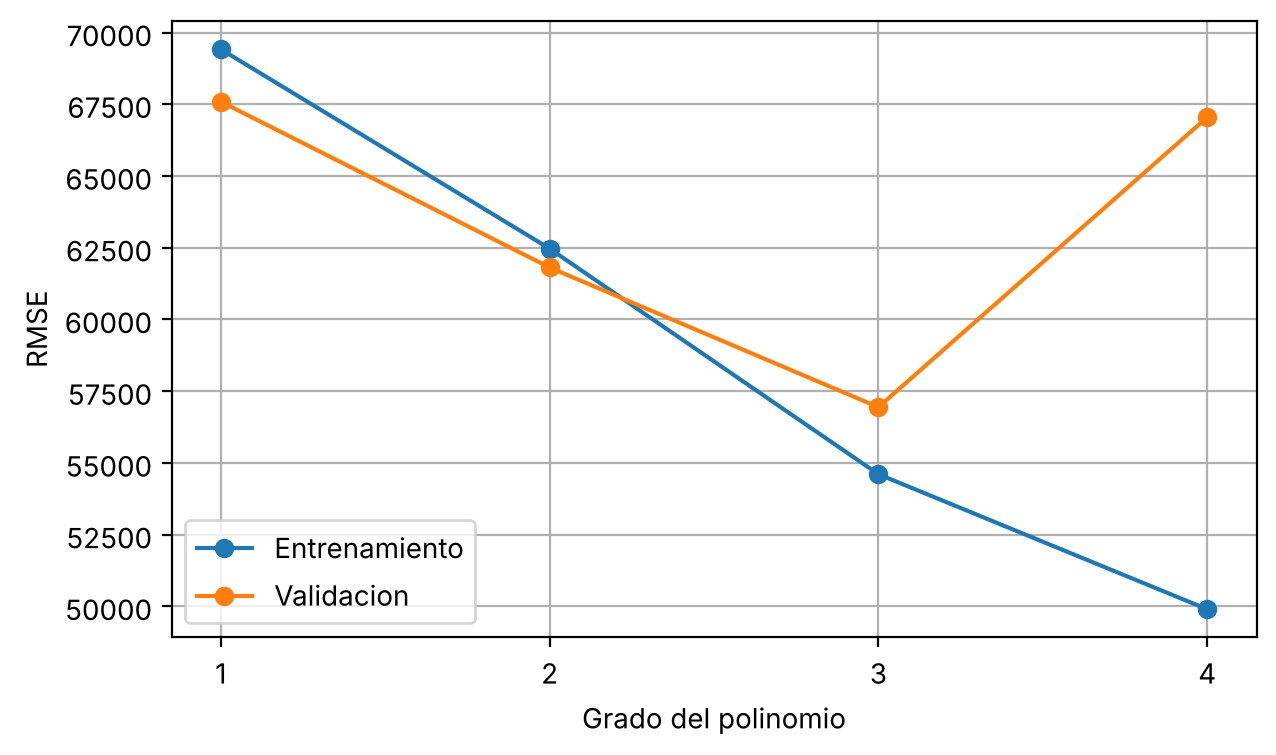

In [ ]:
from sklearn.preprocessing import PolynomialFeatures

# Se separa una parte del entrenamiento para validar, el test no se toca en este bloque
X_sub, X_val, y_sub, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42)

grados = [1, 2, 3, 4]
rmse_sub = []
rmse_val = []

for grado in grados:
    poly = PolynomialFeatures(degree=grado, include_bias=False)
    poly.fit(X_sub)
    P_sub = poly.transform(X_sub)
    P_val = poly.transform(X_val)

    reg = LinearRegression()
    reg.fit(P_sub, y_sub)

    error_sub = np.sqrt(mean_squared_error(y_sub, reg.predict(P_sub)))
    error_val = np.sqrt(mean_squared_error(y_val, reg.predict(P_val)))
    rmse_sub.append(error_sub)
    rmse_val.append(error_val)
    print("Grado", grado, " variables", P_sub.shape[1], " RMSE entrenamiento", round(error_sub), " RMSE validacion", round(error_val))

plt.figure(figsize=(7, 4))
plt.plot(grados, rmse_sub, marker="o", label="Entrenamiento")
plt.plot(grados, rmse_val, marker="o", label="Validacion")
plt.xticks(grados)
plt.xlabel("Grado del polinomio")
plt.ylabel("RMSE")
plt.legend()
plt.grid(True)
plt.show()

Con grado 2 los dos errores bajan, con grado 3 el error de validacion sigue bajando pero ya queda por encima del de entrenamiento. Con grado 4 el error de entrenamiento sigue bajando hasta 49904 pero el de validacion sube a 67047, casi lo mismo que la regresion original que tiene 67590. Eso es sobreajuste, el modelo tiene 2379 variables para unos 13200 distritos y empieza a momorizae los datos de entrenamiento en lugar de la tendencia general.

## Gradiente descendente con el termino L2

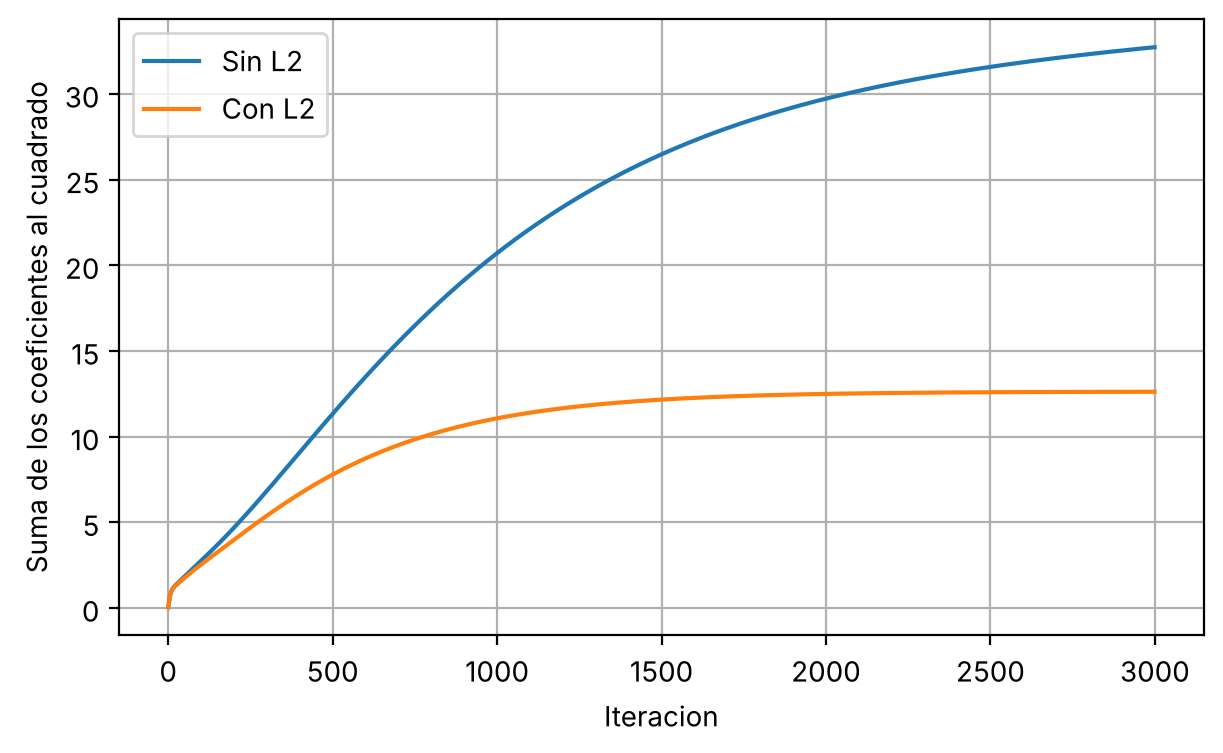

                    sin L2  con L2
longitude           -0.743  -0.413
latitude            -0.559  -0.255
housing_median_age   0.607   0.307
total_rooms          0.503   0.346
total_bedrooms       0.650   0.249
population          -0.545  -0.155
households           0.538   0.232
median_income        5.451   3.379
<1H OCEAN            0.294   0.194
INLAND              -0.354  -0.645
ISLAND               0.065   0.019
NEAR BAY             0.343   0.270
NEAR OCEAN           0.433   0.293


In [ ]:
# Mismo gradiente descendente del laboratorio 4, ahora con varias variables y el termino L2
def gradiente_descendente(X, y, lam, alpha=0.1, iteraciones=3000):
    m = len(y)
    theta_0 = 0.0
    theta = np.zeros(X.shape[1])
    historial = []

    for i in range(iteraciones):
        error = theta_0 + np.dot(X, theta) - y

        d_theta_0 = np.sum(error) / m
        d_theta = np.dot(X.T, error) / m

        theta_0 = theta_0 - alpha * d_theta_0
        # Lo nuevo es lam * theta, en cada paso al coeficiente se le quita una fraccion de si mismo
        theta = theta - alpha * (d_theta + lam * theta)

        historial.append(np.sum(theta ** 2))

    return theta_0, theta, historial

# El precio se pasa a cientos de miles de dolares para que los numeros sean manejables
X_gd = X_train.values
y_gd = y_train.values / 100000

t0_sin, theta_sin, hist_sin = gradiente_descendente(X_gd, y_gd, lam=0)
t0_con, theta_con, hist_con = gradiente_descendente(X_gd, y_gd, lam=0.01)

plt.figure(figsize=(7, 4))
plt.plot(hist_sin, label="Sin L2")
plt.plot(hist_con, label="Con L2")
plt.xlabel("Iteracion")
plt.ylabel("Suma de los coeficientes al cuadrado")
plt.legend()
plt.grid(True)
plt.show()

print(pd.DataFrame({"sin L2": theta_sin, "con L2": theta_con}, index=X_train.columns).round(3))

Sin regularizacion el paso de gradiente descendente solo le resta al coeficiente la derivada del error. Con L2 en cada paso ademas se le resta una fraccion del propio coeficiente, entonces todos los coeficientes son arrastrados hacia cero y el suben mas entre mas grande sea el coeficiente. En la grafica se ve el efecto, sin L2 el tamaño de los coeficientes sigue creciendo durante todas las iteraciones y con L2 se estabiliza en un valor mucho menor. Vemos en la tabla el coeficiente de median_income pasa de 5.45 a 3.38. No todos los coeficientes se reducen por separado si no que se reduce es el tamaño del conjunto.

In [ ]:
from sklearn.linear_model import Ridge, Lasso

# Modelo de grado 4, el que sobreajusta
poly = PolynomialFeatures(degree=4, include_bias=False)
poly.fit(X_sub)

# Se estandarizan los terminos del polinomio para que la penalizacion trate igual a todos los coeficientes
poly_scaler = StandardScaler()
poly_scaler.fit(poly.transform(X_sub))

P_sub = poly_scaler.transform(poly.transform(X_sub))
P_val = poly_scaler.transform(poly.transform(X_val))

alphas_ridge = [0.1, 1, 10, 100, 1000, 10000]
coefs_ridge = []
ridge_sub = []
ridge_val = []

for a in alphas_ridge:
    ridge = Ridge(alpha=a)
    ridge.fit(P_sub, y_sub)
    coefs_ridge.append(ridge.coef_)
    ridge_sub.append(np.sqrt(mean_squared_error(y_sub, ridge.predict(P_sub))))
    ridge_val.append(np.sqrt(mean_squared_error(y_val, ridge.predict(P_val))))
    print("alpha", a, " RMSE entrenamiento", round(ridge_sub[-1]), " RMSE validacion", round(ridge_val[-1]))

alpha 0.1  RMSE entrenamiento 51124  RMSE validacion 57515


alpha 1  RMSE entrenamiento 52399  RMSE validacion 68632


alpha 10  RMSE entrenamiento 54155  RMSE validacion 66800


alpha 100  RMSE entrenamiento 56086  RMSE validacion 56714


alpha 1000  RMSE entrenamiento 59339  RMSE validacion 59332


alpha 10000  RMSE entrenamiento 64357  RMSE validacion 63270


In [ ]:
import warnings
from sklearn.exceptions import ConvergenceWarning

# Con alpha pequeño Lasso avisa que le faltaron iteraciones, se oculta el aviso porque el error ya casi no cambia
warnings.filterwarnings("ignore", category=ConvergenceWarning)

# Esta celda es la mas lenta del notebook, tarda cerca de un minuto
alphas_lasso = [10000, 3000, 1000, 300, 100]
coefs_lasso = []
lasso_sub = []
lasso_val = []
lasso_no_cero = []

# warm_start hace que cada ajuste arranque desde la solucion anterior y sea mas rapido
lasso = Lasso(alpha=10000, max_iter=2000, tol=0.001, warm_start=True)

for a in alphas_lasso:
    lasso.alpha = a
    lasso.fit(P_sub, y_sub)
    coefs_lasso.append(lasso.coef_.copy())
    lasso_sub.append(np.sqrt(mean_squared_error(y_sub, lasso.predict(P_sub))))
    lasso_val.append(np.sqrt(mean_squared_error(y_val, lasso.predict(P_val))))
    lasso_no_cero.append(np.sum(lasso.coef_ != 0))
    print("alpha", a, " RMSE entrenamiento", round(lasso_sub[-1]), " RMSE validacion", round(lasso_val[-1]),
          " coeficientes distintos de cero", lasso_no_cero[-1], "de", P_sub.shape[1])

alpha 10000  RMSE entrenamiento 72667  RMSE validacion 70604  coeficientes distintos de cero 11 de 2379


alpha 3000  RMSE entrenamiento 67648  RMSE validacion 65550  coeficientes distintos de cero 26 de 2379


alpha 1000  RMSE entrenamiento 63106  RMSE validacion 61644  coeficientes distintos de cero 65 de 2379


alpha 300  RMSE entrenamiento 59327  RMSE validacion 58923  coeficientes distintos de cero 119 de 2379


alpha 100  RMSE entrenamiento 56995  RMSE validacion 57202  coeficientes distintos de cero 187 de 2379


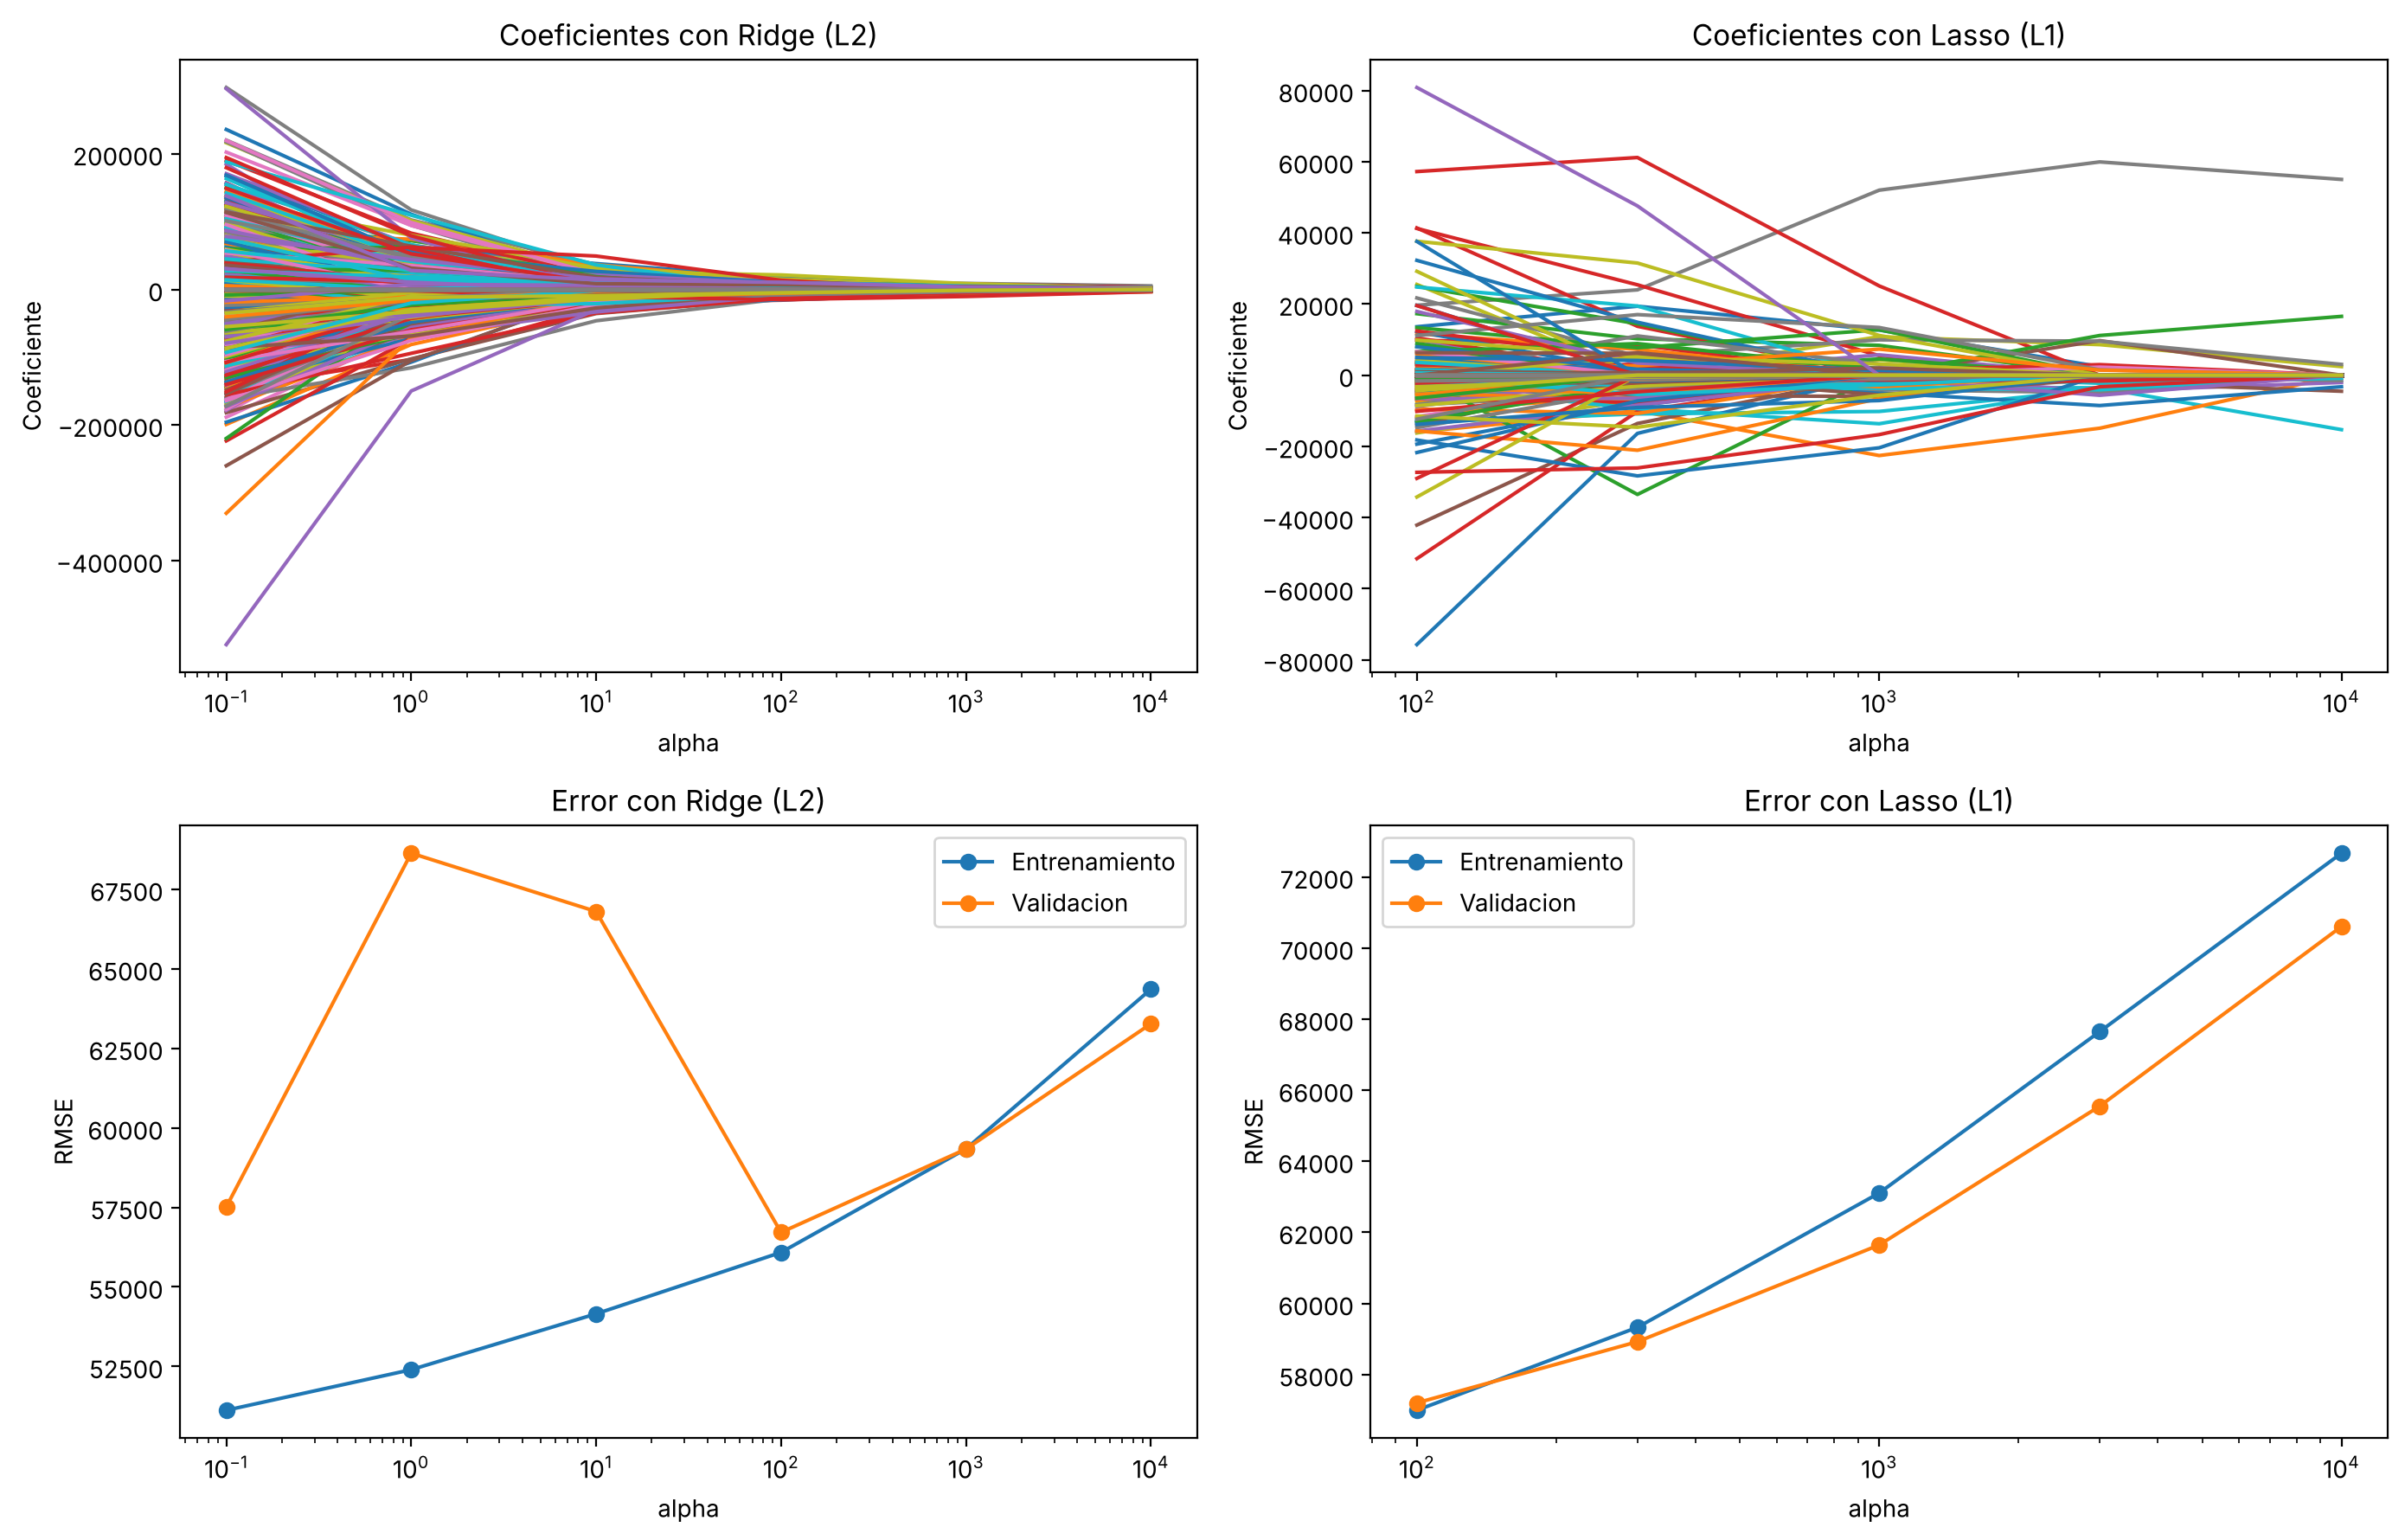

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

axes[0, 0].plot(alphas_ridge, coefs_ridge)
axes[0, 0].set_xscale("log")
axes[0, 0].set_title("Coeficientes con Ridge (L2)")
axes[0, 0].set_xlabel("alpha")
axes[0, 0].set_ylabel("Coeficiente")

axes[0, 1].plot(alphas_lasso, coefs_lasso)
axes[0, 1].set_xscale("log")
axes[0, 1].set_title("Coeficientes con Lasso (L1)")
axes[0, 1].set_xlabel("alpha")
axes[0, 1].set_ylabel("Coeficiente")

axes[1, 0].plot(alphas_ridge, ridge_sub, marker="o", label="Entrenamiento")
axes[1, 0].plot(alphas_ridge, ridge_val, marker="o", label="Validacion")
axes[1, 0].set_xscale("log")
axes[1, 0].set_title("Error con Ridge (L2)")
axes[1, 0].set_xlabel("alpha")
axes[1, 0].set_ylabel("RMSE")
axes[1, 0].legend()

axes[1, 1].plot(alphas_lasso, lasso_sub, marker="o", label="Entrenamiento")
axes[1, 1].plot(alphas_lasso, lasso_val, marker="o", label="Validacion")
axes[1, 1].set_xscale("log")
axes[1, 1].set_title("Error con Lasso (L1)")
axes[1, 1].set_xlabel("alpha")
axes[1, 1].set_ylabel("RMSE")
axes[1, 1].legend()

plt.tight_layout()
plt.show()

En las graficas de arriba estan los coeficientes y en las de abajo el error. Con Ridge todos los coeficientes se encogen al mismo tiempo y de forma suave a medida que alpha crece. Con Lasso los coeficientes se van apagando, con alpha de 10000 solo quedan 11 de los 2379 distintos de cero y con alpha de 100 quedan 187. Esa es la diferencia principal, L2 reduce todos los coeficientes y L1 ademas selecciona variables.

En el error, con Lasso las curvas de entrenamiento y validacion van juntas y el minimo de validacion es 57202 con alpha de 100. Con Ridge el error de entrenamiento cambia suave pero el de validacion da saltos para alpha pequeño, y el minimo es 56714 con alpha de 100.

In [ ]:
# Variables colineales del bloque de PCA, se usa el modelo original de 13 variables para poder leer los coeficientes
colineales = ["total_rooms", "total_bedrooms", "population", "households"]

ridge_13 = Ridge(alpha=10)
ridge_13.fit(X_train, y_train)

lasso_13 = Lasso(alpha=300, max_iter=10000)
lasso_13.fit(X_train, y_train)

tabla_colineales = pd.DataFrame({"Lineal": lin_reg.coef_,
                                 "Ridge": ridge_13.coef_,
                                 "Lasso": lasso_13.coef_}, index=X_train.columns)
print(tabla_colineales.loc[colineales].round(0))

                   Lineal     Ridge    Lasso
total_rooms     -184259.0  -16370.0      0.0
total_bedrooms   452428.0  173385.0  85142.0
population     -1401276.0 -296539.0     -0.0
households       412021.0   94197.0      0.0


En la regresion lineal las cuatro variables +ienen coeficientes muy grandes y de signos opuestos. Ridge las conserva todas pero reduce mucho los coeficientes, el de population pasa de -1401276 a -296539. Lasso se queda solo con total_bedrooms y pone las otras tres en cero, es decir que escoge una representante del grupo. Es parecido a lo que hizo PCA al resumir las cuatro en una sola componente.

## Pipeline

In [ ]:
# El mejor alpha es el que da menor error de validacion
mejor_alpha_ridge = alphas_ridge[np.argmin(ridge_val)]
mejor_alpha_lasso = alphas_lasso[np.argmin(lasso_val)]
print("Mejor alpha Ridge", mejor_alpha_ridge)
print("Mejor alpha Lasso", mejor_alpha_lasso)

modelo_ridge = Pipeline([
    ("preparacion", preparacion),
    ("polinomio", PolynomialFeatures(degree=4, include_bias=False)),
    ("escala", StandardScaler()),
    ("ridge", Ridge(alpha=mejor_alpha_ridge)),
])

modelo_lasso = Pipeline([
    ("preparacion", preparacion),
    ("polinomio", PolynomialFeatures(degree=4, include_bias=False)),
    ("escala", StandardScaler()),
    ("lasso", Lasso(alpha=mejor_alpha_lasso, max_iter=2000, tol=0.001)),
])

# Se ajustan con todo el conjunto de entrenamiento y los datos crudos
modelo_ridge.fit(train, y_train)
modelo_lasso.fit(train, y_train)

print("Ridge R2 entrenamiento", round(modelo_ridge.score(train, y_train), 3))
print("Lasso R2 entrenamiento", round(modelo_lasso.score(train, y_train), 3))

Mejor alpha Ridge 100
Mejor alpha Lasso 100


Ridge R2 entrenamiento 0.767


Lasso R2 entrenamiento 0.758


## Analisis

La respuesta es que si se puede ajustar a otro modelo. Al agregar terminos polinomiales el error de validacion baja de 67590 a 56944 con grado 3, lo que indica que la relacion entre las variables y el precio no es solo lineal. Pero si se aumenta la complejidad sin control aparece el sobreajuste, con grado 4 el error de validacion vuelve al nivel de la regresion original.

Ridge y Lasso corrigen ese sobreajuste penalizando los coeficientes grandes. La diferencia entre los dos se ve en las graficas y en las variables, Ridge encoge todos los coeficientes y reparte el peso entre variables parecidas, Lasso lleva coeficientes hasta cero y se queda con pocas variables. Los valores de alpha se escogieron con el conjunto de validacion, sin usar el test y los modelos finales quedaron organizados en un Pipeline que recibe los datos crudos del dataset


# 5. Comparacion final

In [ ]:
# Predicciones de los cuatro modelos sobre el mismo conjunto de test
pred_lineal = lin_reg.predict(X_test)
pred_pca = modelo_pca.predict(T_test)
pred_ridge = modelo_ridge.predict(test)
pred_lasso = modelo_lasso.predict(test)

predicciones = {"Regresion lineal": pred_lineal,
                "Modelo reducido PCA": pred_pca,
                "Ridge": pred_ridge,
                "Lasso": pred_lasso}

y_real = y_test.values

for nombre in predicciones:
    pred = predicciones[nombre]
    rmse = np.sqrt(mean_squared_error(y_real, pred))
    r2 = 1 - np.sum((y_real - pred) ** 2) / np.sum((y_real - y_real.mean()) ** 2)
    print(nombre, " RMSE", round(rmse), " R2", round(r2, 3))

# Los tres errores mas grandes de cada modelo
for nombre in predicciones:
    errores = np.abs(y_real - predicciones[nombre])
    print(nombre, np.sort(errores)[-3:].round(0))

Regresion lineal  RMSE 67347  R2 0.652
Modelo reducido PCA  RMSE 78928  R2 0.522
Ridge  RMSE 68869  R2 0.636
Lasso  RMSE 58201  R2 0.74
Regresion lineal [319373. 328599. 335892.]
Modelo reducido PCA [370586. 373466. 380309.]
Ridge [ 311017.  330277. 2607934.]
Lasso [320769. 346003. 835104.]


Lasso es el mejor de los cuatro con un RMSE de 58201 y R2 de 0.74. La regresion lineal queda en 67347, Ridge en 68869 y el modelo reducido en 78928. En los errores mas grandes se ve que Ridge tiene un distrito con un error de 2.6 millones de dolares y Lasso uno de 835 mil, mientras que en los otros dos modelos el error maximo es de menos de 400 mil. Los modelos de grado 4 pueden dar predicciones absurdas para distritos muy distintos al resto.

Modelo reducido PCA  diferencia media 11575  intervalo 95% 10471 12666
Ridge  diferencia media 1621  intervalo 95% -12360 29583
Lasso  diferencia media -9040  intervalo 95% -11324 -5699


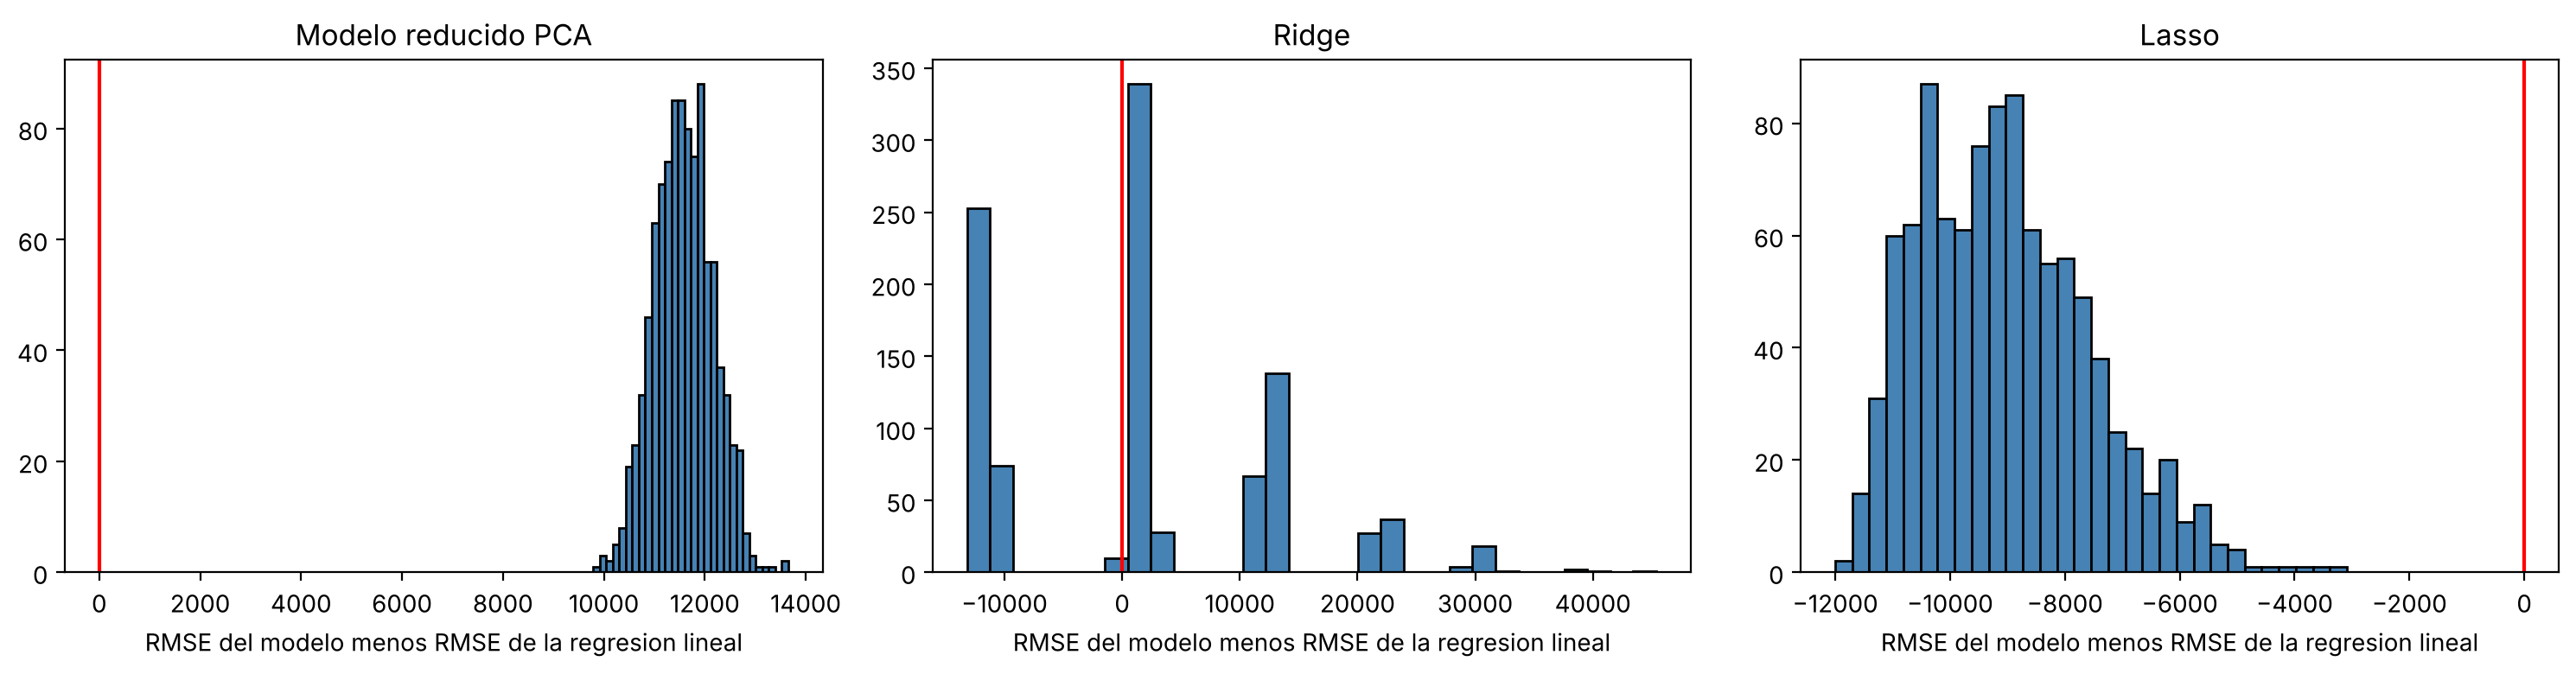

In [ ]:
# Bootstrap -> se remuestrea el test con reemplazo y se guarda la diferencia de RMSE contra la regresion lineal
np.random.seed(42)
n = len(y_real)
diferencias = {"Modelo reducido PCA": [], "Ridge": [], "Lasso": []}

for i in range(1000):
    idx = np.random.randint(0, n, n)
    rmse_lineal = np.sqrt(mean_squared_error(y_real[idx], pred_lineal[idx]))
    for nombre in diferencias:
        rmse_modelo = np.sqrt(mean_squared_error(y_real[idx], predicciones[nombre][idx]))
        diferencias[nombre].append(rmse_modelo - rmse_lineal)

for nombre in diferencias:
    limite_inferior = np.percentile(diferencias[nombre], 2.5)
    limite_superior = np.percentile(diferencias[nombre], 97.5)
    print(nombre, " diferencia media", round(np.mean(diferencias[nombre])),
          " intervalo 95%", round(limite_inferior), round(limite_superior))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
i = 0
for nombre in diferencias:
    axes[i].hist(diferencias[nombre], bins=30, color="steelblue", edgecolor="black")
    axes[i].axvline(0, color="red")
    axes[i].set_title(nombre)
    axes[i].set_xlabel("RMSE del modelo menos RMSE de la regresion lineal")
    i = i + 1
plt.tight_layout()
plt.show()

Si el intervalo no incluye el cero la diferencia es significativa. El modelo reducido es peor que la regresion lineal, teniendo hasta 12666 dolares mas de error. Lasso es mejor, entre 5699 y 11324 dolares menos de error. Para Ridge el intervalo va de -12360 a 29583 e incluye el cero, asi que no sabemos si es diferente de la regresion lineal, y el intervalo es tan ancho porque su error depende de si el distrito del error enorme cae o no en la muestra.

In [ ]:
# Terminos que conserva Lasso
nombres = modelo_lasso.named_steps["polinomio"].get_feature_names_out(X_train.columns)
coef_lasso = pd.Series(modelo_lasso.named_steps["lasso"].coef_, index=nombres)
conservados = coef_lasso[coef_lasso != 0]
print("Terminos conservados", len(conservados), "de", len(coef_lasso))

# Los 10 terminos con coeficiente mas grande
print(conservados.abs().sort_values(ascending=False).head(10).round(0))

# Peso total de los terminos en los que aparece cada variable numerica
for col in cols_num:
    peso = 0
    for termino in conservados.index:
        if col in termino:
            peso = peso + abs(conservados[termino])
    print(col, round(peso))

Terminos conservados 193 de 2379
median_income^2                                57158.0
housing_median_age population median_income    56170.0
longitude^2 housing_median_age NEAR BAY        54853.0
NEAR BAY^4                                     52359.0
longitude latitude^2 NEAR BAY                  51501.0
housing_median_age median_income               47234.0
housing_median_age NEAR BAY^3                  46040.0
total_rooms median_income                      45091.0
housing_median_age^2 population^2              36816.0
longitude latitude^3                           33077.0
dtype: float64
longitude 493266
latitude 388243
housing_median_age 833771
total_rooms 170823
total_bedrooms 217185
population 383825
households 108980
median_income 654224


Lasso conserva 193 de los 2379 terminos. Los de mayor peso son combinaciones de median_income, housing_median_age, longitud, latitud y la categoria NEAR BAY. Al sumar el peso por variable las que mas aparecen son la edad, el ingreso y la ubicacion, y las que menos son households, total_rooms y total_bedrooms.

## Analisis
Las variables que conserva Lasso si se relacionan con lo que mostro PCA, pero no en el mismo orden. PCA separo cuatro grupos, tamaño, ubicacion, ingreso y edad. Lasso le da el mayor peso al ingreso, la edad y la ubicacion, que son PC3, PC4 y PC2, y le da poco peso a las variables de tamaño, que formaban PC1. Esto coincide con el modelo reducido donde los coeficientes grandes eran los de PC3 y PC4. La razon es que PCA ordena por varianza sin mirar el precio y Lasso escoge las variables segun que tanto ayudan a predecir el precio. Ademas dentro del grupo colineal Lasso se queda con pocas variables, igual que PCA las agrupo en una sola componente.

Sobre la regresion lineal original, la conclusion cambia parcialmenete. Es cierto que no sobreajusta y que su score de 0.65 es aceptable, pero ahora hay evidencia de que no es el mejor modelo posible ya qye lo hemos representado mejor con alternativos. Lasso con terminos polinomiales llega a 0.74 y el bootstrap dice que esa mejora es significativa, entonces la relacion con el precio tiene una parte no lineal que la regresion original no captura. Tambien se confirma que sus coeficientes no se deben interpretar debido a su colinealidad. Lo que si se mantiene es que es un modelo estable y  sus errores maximos son mucho menores que los de Ridge y Lasso de grado 4.

En cuanto a la interpretacion, pasar de la regresion lineal al modelo reducido cuesta 0.13 puntos de R2 y unos 11500 dolares mas de error, y frente a Lasso la diferencia es de 0.22 puntos de R2 y unos 20700 dolares. Si no es necesario demaciada especializacion nos podemos quedar con el modelo reducido, porque se puede explicar con cuatro ideas sencillas (tamaño del distrito, ubicacion, ingreso y edad de las viviendas) y cada coeficiente se puede leer por separado, aclarando que se equivoca en promedio unos 79000 dolares, que puede ser considerable o no segun a quien le interese. Lasso predice mejor pero tiene 193 terminos de grado 4 que no se pueden explicar,lo cual es incomodo, y la regresion lineal de 13 variables tiene coeficientes que se pueden confundir. Si lo que se necesita es la mejor prediccion y no una explicacion, usaria Lasso.